# Prioritising Healthcare Affordability Outreach
### Recall-focused random forest classification and priority-population profiles · DBA3803 Group 12

## Overview

### Identified Business Problem
Healthcare providers have limited staff and resources to help people with financial assistance and care navigation. While low income and a lack of insurance may be useful warning signs, there are often more factors at play that influence a person’s ability to access healthcare. For example, a [2023 KFF consumer survey](https://www.kff.org/affordable-care-act/kff-survey-of-consumer-experiences-with-health-insurance/) reported that 58% of insured adults experienced at least one problem using their coverage, illustrating how those insured may still face cost barriers to medical care. 

As such, our project aims to develop a model that allows the provider to prioritize outreach by identifying individuals with the highest likelihood of requiring financial assistance for healthcare. This was done by looking at age, financial circumstances, health and an individual’s access to care, allowing us to take into account more factors beyond a person’s insurance status to build a more robust prediction model.

### Project Focus
Given limited outreach capacity, how can a U.S. healthcare provider better identify and prioritise individuals who may require affordability-related support, and what distinct profiles exist among those prioritised for outreach?

As emphasised in our report, the primary business objectives are to:
Improve outreach resource allocation by identifying individuals who may require affordability-related support more effectively than random selection or insurance-only targeting.
Better understand the priority population by identifying distinct profiles based on demographic, socioeconomic, healthcare-access and health characteristics, to inform differentiated outreach strategies.

## Part 0: Loading Packages and Requirements

In [1]:
from pathlib import Path
import sys, json, time, hashlib, platform
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
import sklearn
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, roc_curve, confusion_matrix,
                             make_scorer, silhouette_score, adjusted_rand_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from kmodes.kprototypes import KPrototypes

RANDOM_STATE = 1
N_JOBS = 4
DATA_DIR = Path('.')
TRAIN_PATH = DATA_DIR / 'nhis_2023_2024.csv'
TEST_PATH = DATA_DIR / 'nhis_2025.csv'
CAPACITIES = (0.05, 0.10, 0.20, 0.30, 0.40, 0.50)
SELECTION_CAPACITIES = (0.05, 0.10, 0.20)
PROFILE_FRACTION = 0.20
TEST_OPENED = False
FIT_LOG = []

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print(f'Python {platform.python_version()} | scikit-learn {sklearn.__version__}')
print('Only the development CSV will be opened initially.')

Python 3.14.7 | scikit-learn 1.9.0
Only the development CSV will be opened initially.


## Part 1: Data Inspection
### Data source, observations and variables
The supplied files are extracts of the **IPUMS National Health Interview Survey (NHIS)**. After filtering, one observation is one sample adult with a valid target answer and positive adult survey weight. We use the supplied year labels to separate development and evaluation. Identifiers distinguish records, rather than explain affordability.

| Role | Variables | Reason |
|---|---|---|
| Target | `YBARCARE` | The reported cost-related unmet medical need we want to identify |
| Predictors | `REGION`, `AGE`, `SEX`, `HISPRACE`, `EDUC`, `EMPSTAT`, `POVERTY`, `HEALTH`, `USUALPL`, `HINOTCOVE` | Information potentially available in an intake or patient record |
| Year | `YEAR` | Determines the time split; excluded from model inputs |
| Identifiers | `SERIAL`, `NHISHID`, `PERNUM`, `NHISPID`, `HHX` | Record checks only; excluded from modelling and clustering |
| Survey design | `SAMPWEIGHT`, `STRATA`, `PSU` | Population-oriented summaries and study design, not individual-need predictors |
| Sample flags | `ASTATFLG`, `CSTATFLG` | Select the appropriate sample; excluded as predictors |

Additional notes:
- `POVERTY` is a category of family income relative to the poverty threshold, not an exact income. 
- `HINOTCOVE = 1` means covered and `= 2` means no coverage. 
- `EMPSTAT = 200` means not employed; this includes people outside the labour force, not only people looking for work. 
- `AGE = 85` is top-coded: it should be read as 85 or older. 

See the IPUMS references in the appendix.

In [2]:
PREDICTORS = ['REGION', 'AGE', 'SEX', 'HISPRACE', 'EDUC',
              'EMPSTAT', 'POVERTY', 'HEALTH', 'USUALPL', 'HINOTCOVE']
CATEGORICAL = [c for c in PREDICTORS if c != 'AGE']
ID_COLUMNS = ['SERIAL', 'NHISHID', 'PERNUM', 'NHISPID', 'HHX']
DESIGN_COLUMNS = ['SAMPWEIGHT', 'STRATA', 'PSU']
EXCLUDED = ['YBARCARE', 'target', 'YEAR', 'ASTATFLG', 'CSTATFLG'] + ID_COLUMNS + DESIGN_COLUMNS
REQUIRED = set(PREDICTORS + ['YEAR', 'ASTATFLG', 'YBARCARE', 'SAMPWEIGHT', 'NHISPID'])

def verify_structure(data, expected_years, name):
    missing = REQUIRED.difference(data.columns)
    if missing:
        raise ValueError(f'{name} missing columns: {sorted(missing)}')
    years = set(data['YEAR'].dropna().astype(int))
    if years != set(expected_years):
        raise ValueError(f'{name}: years {years}, expected {expected_years}')

if not TRAIN_PATH.exists():
    raise FileNotFoundError('Place the notebook beside nhis_2023_2024.csv.')
development_raw = pd.read_csv(TRAIN_PATH, dtype={'NHISPID': str})
verify_structure(development_raw, {2023, 2024}, 'Development file')
print('Development file shape:', development_raw.shape)
display(development_raw[['YEAR'] + PREDICTORS + ['YBARCARE']].head())
display(pd.DataFrame({'dtype': development_raw.dtypes.astype(str),
                      'raw_missing': development_raw.isna().sum()}))
display(development_raw[['AGE', 'SAMPWEIGHT']].describe().T)
print('Repeated raw person identifiers:', development_raw['NHISPID'].duplicated().sum())

Development file shape: (78203, 22)


,YEAR,REGION,AGE,SEX,HISPRACE,EDUC,EMPSTAT,POVERTY,HEALTH,USUALPL,HINOTCOVE,YBARCARE
0,2023,4,39,1,2,301,100,35,2,1,1,1
1,2023,4,15,2,2,0,0,35,1,2,1,1
2,2023,3,71,2,2,202,200,12,5,2,1,1
3,2023,1,36,1,2,201,100,34,4,2,1,1
4,2023,4,57,2,2,201,100,34,3,2,1,1


,dtype,raw_missing
YEAR,int64,0
SERIAL,int64,0
STRATA,int64,0
PSU,int64,0
NHISHID,str,0
REGION,int64,0
PERNUM,int64,0
NHISPID,str,0
HHX,str,0
SAMPWEIGHT,int64,0


,count,mean,std,min,25%,50%,75%,max
AGE,"78,203.0000",45.5979,44.2325,0.0000,24.0000,45.0000,65.0000,999.0000
SAMPWEIGHT,"78,203.0000","8,467.7091","5,679.5261",265.0000,"4,362.0000","7,086.0000","10,858.0000","39,925.0000"


Repeated raw person identifiers: 0


## Part 2: Clean Data
The following rules are fixed from the IPUMS variable definitions, rather than estimated from evaluation data:

1. Keep sample adults (`ASTATFLG == 1`) and valid Yes/No target answers. An unknown answer cannot tell us the correct class, so it is excluded.
2. Convert Yes to target 1 and No to target 0. No other variable changes this label.
3. Replace documented non-response codes with missing values. For example, an unknown age coded 999 is not a 999-year-old adult.
4. Keep records with a positive survey weight to maintain the original sample definition and weighted descriptive analysis.
5. Retain missing predictors. Later, the model pipeline learns the median age from its training rows and uses a fixed missing-category label for other inputs.
6. Repeated records were not removed as different individuals could have the same survey answers.

In [3]:
INVALID_CODES = {
    'REGION': [8, 9], 'AGE': [997, 998, 999], 'SEX': [7, 8, 9],
    'HISPRACE': [97, 98, 99], 'EDUC': [0, 996, 997, 998, 999],
    'EMPSTAT': [0, 900, 997, 998, 999], 'POVERTY': [0, 98, 99],
    'HEALTH': [7, 8, 9], 'USUALPL': [0, 7, 8, 9], 'HINOTCOVE': [0, 7, 8, 9]
}

def prepare_nhis(raw):
    data = raw.loc[raw['ASTATFLG'].eq(1) & raw['YBARCARE'].isin([1, 2])].copy()
    data['target'] = data['YBARCARE'].map({1: 0, 2: 1}).astype('int8')
    for column, codes in INVALID_CODES.items():
        data[column] = pd.to_numeric(data[column], errors='coerce')
        data[column] = data[column].mask(data[column].isin(codes))
    data['SAMPWEIGHT'] = pd.to_numeric(data['SAMPWEIGHT'], errors='coerce')
    return data.loc[data['SAMPWEIGHT'].gt(0)].reset_index(drop=True)

def cleaning_summary(raw, cleaned):
    adult = raw['ASTATFLG'].eq(1)
    return pd.DataFrame({'stage': ['Raw records', 'Sample adults', 'Valid adult target',
                                   'Retained after positive-weight check'],
                         'rows': [len(raw), int(adult.sum()),
                                  int((adult & raw['YBARCARE'].isin([1, 2])).sum()), len(cleaned)]})

development = prepare_nhis(development_raw)
assert development['target'].isin([0, 1]).all()
assert development['AGE'].dropna().between(18, 85).all()
assert development['NHISPID'].notna().all() and development['NHISPID'].is_unique
assert not set(PREDICTORS).intersection(EXCLUDED)
display(cleaning_summary(development_raw, development))
missing_table = pd.DataFrame({'missing_n': development[PREDICTORS].isna().sum(),
                              'missing_%': development[PREDICTORS].isna().mean() * 100})
display(missing_table.sort_values('missing_%', ascending=False))
display(development[PREDICTORS].nunique().rename('distinct_observed_values').to_frame())

,stage,rows
0,Raw records,78203
1,Sample adults,62151
2,Valid adult target,61630
3,Retained after positive-weight check,61630


,missing_n,missing_%
EMPSTAT,1982,3.2160
EDUC,281,0.4559
HINOTCOVE,161,0.2612
AGE,109,0.1769
USUALPL,46,0.0746
HEALTH,34,0.0552
SEX,11,0.0178
REGION,0,0.0000
HISPRACE,0,0.0000
POVERTY,0,0.0000


,distinct_observed_values
REGION,4
AGE,68
SEX,2
HISPRACE,7
EDUC,10
EMPSTAT,2
POVERTY,14
HEALTH,5
USUALPL,3
HINOTCOVE,2


## Part 3: Train / Validation / Test Split

We aimed to maintain a strict separation of data and defined clear roles for each set of data used to ensure project clarity as well as to prevent data leakage between the training/validation and test data.

| Sample | Role | Usage |
|---|---|---|
| 2023 | Initial training and five-fold cross-validation | Learn preprocessing and tune model settings using training folds only |
| 2024 | Later-year validation | Compare tuned models and forest finalists; diagnose weaknesses; define descriptive profiles |
| 2023–2024 | Final refit | Relearn the chosen model and baseline parameters using both development years |
| 2025 | Out-of-time evaluation | Apply the frozen procedure and report results; never fit, select, or alter settings |

To conduct cross-validation (CV), 2023 data is divided into into five folds. We preserved the approximate proportion of positive cases in each fold to account for the data imbalance in adults with reported barriers. The pipeline relearns missing-value replacements and category columns inside each training fold.

In [4]:
initial_train = development.loc[development['YEAR'].eq(2023)].reset_index(drop=True)
validation = development.loc[development['YEAR'].eq(2024)].reset_index(drop=True)
X_train, y_train = initial_train[PREDICTORS], initial_train['target']
X_validation, y_validation = validation[PREDICTORS], validation['target']
assert set(initial_train['YEAR']) == {2023} and set(validation['YEAR']) == {2024}
assert set(initial_train['NHISPID']).isdisjoint(validation['NHISPID'])

def fit_development(estimator, X, y, records, name):
    assert not TEST_OPENED, 'Fitting is locked after the evaluation file is opened.'
    assert set(records['YEAR']).issubset({2023, 2024})
    assert len(X) == len(y) == len(records)
    assert list(X.columns) == PREDICTORS
    FIT_LOG.append({'step': name, 'years': sorted(records['YEAR'].unique().tolist()), 'rows': len(X)})
    return estimator.fit(X, y)

display(development.groupby('YEAR').agg(adults=('target', 'size'),
                                       cases=('target', 'sum'), prevalence=('target', 'mean')))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for train_idx, held_idx in cv.split(X_train, y_train):
    assert set(train_idx).isdisjoint(held_idx)
print('Five 2023-only folds are defined. No 2025 data have been loaded.')

,adults,cases,prevalence
YEAR,,,
2023,29276,1716,0.0586
2024,32354,2195,0.0678


Five 2023-only folds are defined. No 2025 data have been loaded.


## Part 4: Data Visualization

- Unweighted counts describe the supplied respondent sample. 
- Survey-weighted rates use `SAMPWEIGHT` to better describe the represented adult population.
- The charts below use 2023–2024 data only, as 2025 data is kept separate for final model testing to prevent data leakage.

,year,adults,cases,sample_rate,weighted_rate
0,2023,29276,1716,0.0586,0.0633
1,2024,32354,2195,0.0678,0.0739


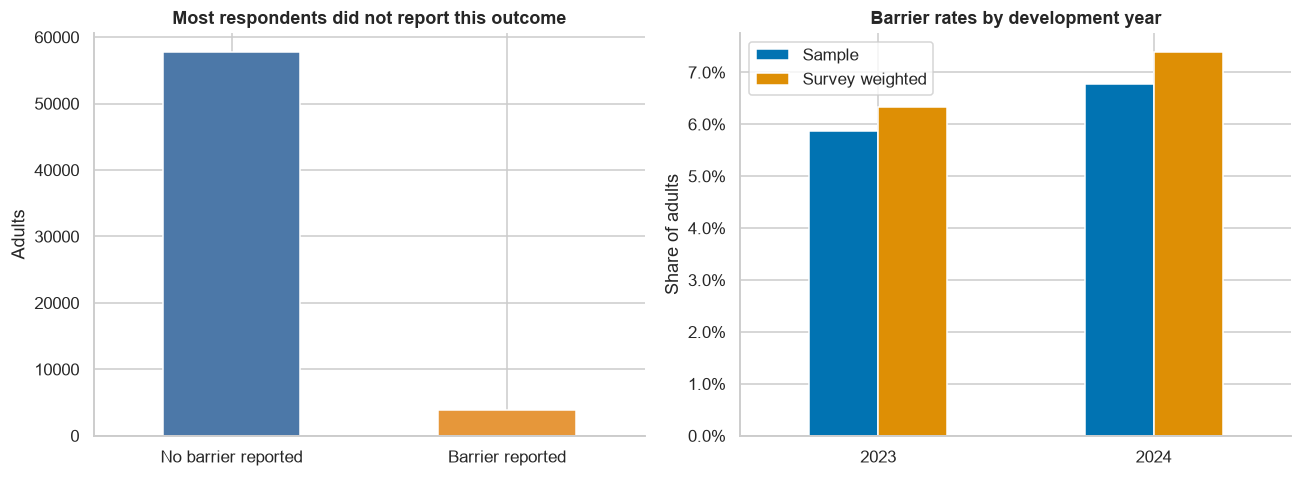

**Interpretation:** The development sample contains **61,630 adults**, including **3,911 reported cases (6.35%)**. A model that says No for everyone would appear accurate while finding no cases. Our evaluation must therefore measure case finding within the contact list.

In [5]:
LABELS = {
 'REGION': {1: 'Northeast', 2: 'Midwest', 3: 'South', 4: 'West'},
 'SEX': {1: 'Male', 2: 'Female'},
 'HISPRACE': {1: 'Hispanic', 2: 'Non-Hispanic White', 3: 'Non-Hispanic Black',
              4: 'Non-Hispanic Asian', 5: 'Non-Hispanic AI/AN',
              6: 'Non-Hispanic AI/AN + other', 7: 'Non-Hispanic other/multiple'},
 'EMPSTAT': {100: 'Employed', 200: 'Not employed'},
 'HEALTH': {1: 'Excellent', 2: 'Very good', 3: 'Good', 4: 'Fair', 5: 'Poor'},
 'USUALPL': {1: 'No usual place', 2: 'Has usual place', 3: 'More than one place'},
 'HINOTCOVE': {1: 'Covered', 2: 'Not covered'},
 'POVERTY': {11: '<0.50', 12: '0.50–0.74', 13: '0.75–0.99', 21: '1.00–1.24',
             22: '1.25–1.49', 23: '1.50–1.74', 24: '1.75–1.99', 31: '2.00–2.49',
             32: '2.50–2.99', 33: '3.00–3.49', 34: '3.50–3.99', 35: '4.00–4.49',
             36: '4.50–4.99', 37: '5.00+'},
 'EDUC': {103: 'Grades 1–11', 116: 'Grade 12, no diploma', 201: 'High-school diploma',
          202: 'GED', 301: 'Some college', 302: 'Associate, vocational',
          303: 'Associate, academic', 400: "Bachelor's", 510: "Master's",
          520: 'Professional / doctorate'}
}

def category_label(value, column):
    if pd.isna(value):
        return 'Missing'
    return LABELS.get(column, {}).get(int(value), f'Code {int(value)}')

def weighted_binary_rate(data):
    return float(np.average(data['target'], weights=data['SAMPWEIGHT']))

def weighted_rate_by(data, column):
    # Retain missing answers as a visible group rather than silently deleting them.
    d = data[[column, 'target', 'SAMPWEIGHT']].copy()
    d['weighted_positive'] = d['target'] * d['SAMPWEIGHT']
    table = d.groupby(column, dropna=False, observed=True).agg(
        n=('target', 'size'), positive_cases=('target', 'sum'),
        unweighted_rate=('target', 'mean'), total_weight=('SAMPWEIGHT', 'sum'),
        weighted_positive=('weighted_positive', 'sum')).reset_index()
    table['weighted_rate'] = table['weighted_positive'] / table['total_weight']
    table['label'] = table[column].map(lambda x: category_label(x, column))
    return table

prevalence = pd.DataFrame([{'year': str(year), 'adults': len(g), 'cases': int(g['target'].sum()),
                           'sample_rate': g['target'].mean(),
                           'weighted_rate': weighted_binary_rate(g)}
                          for year, g in development.groupby('YEAR')])
display(prevalence)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
development['target'].value_counts().sort_index().plot.bar(
    ax=axes[0], color=['#4C78A8', '#E6973A'], rot=0)
axes[0].set(xticklabels=['No barrier reported', 'Barrier reported'], ylabel='Adults',
            xlabel='', title='Most respondents did not report this outcome')
prevalence.set_index('year')[['sample_rate', 'weighted_rate']].plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Barrier rates by development year', ylabel='Share of adults', xlabel='')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(['Sample', 'Survey weighted'])
plt.tight_layout(); plt.show()
display(Markdown(f"**Interpretation:** The development sample contains **{len(development):,} adults**, "
                 f"including **{development['target'].sum():,} reported cases ({development['target'].mean():.2%})**. "
                 'A model that says No for everyone would appear accurate while finding no cases. '
                 'Our evaluation must therefore measure case finding within the contact list.'))

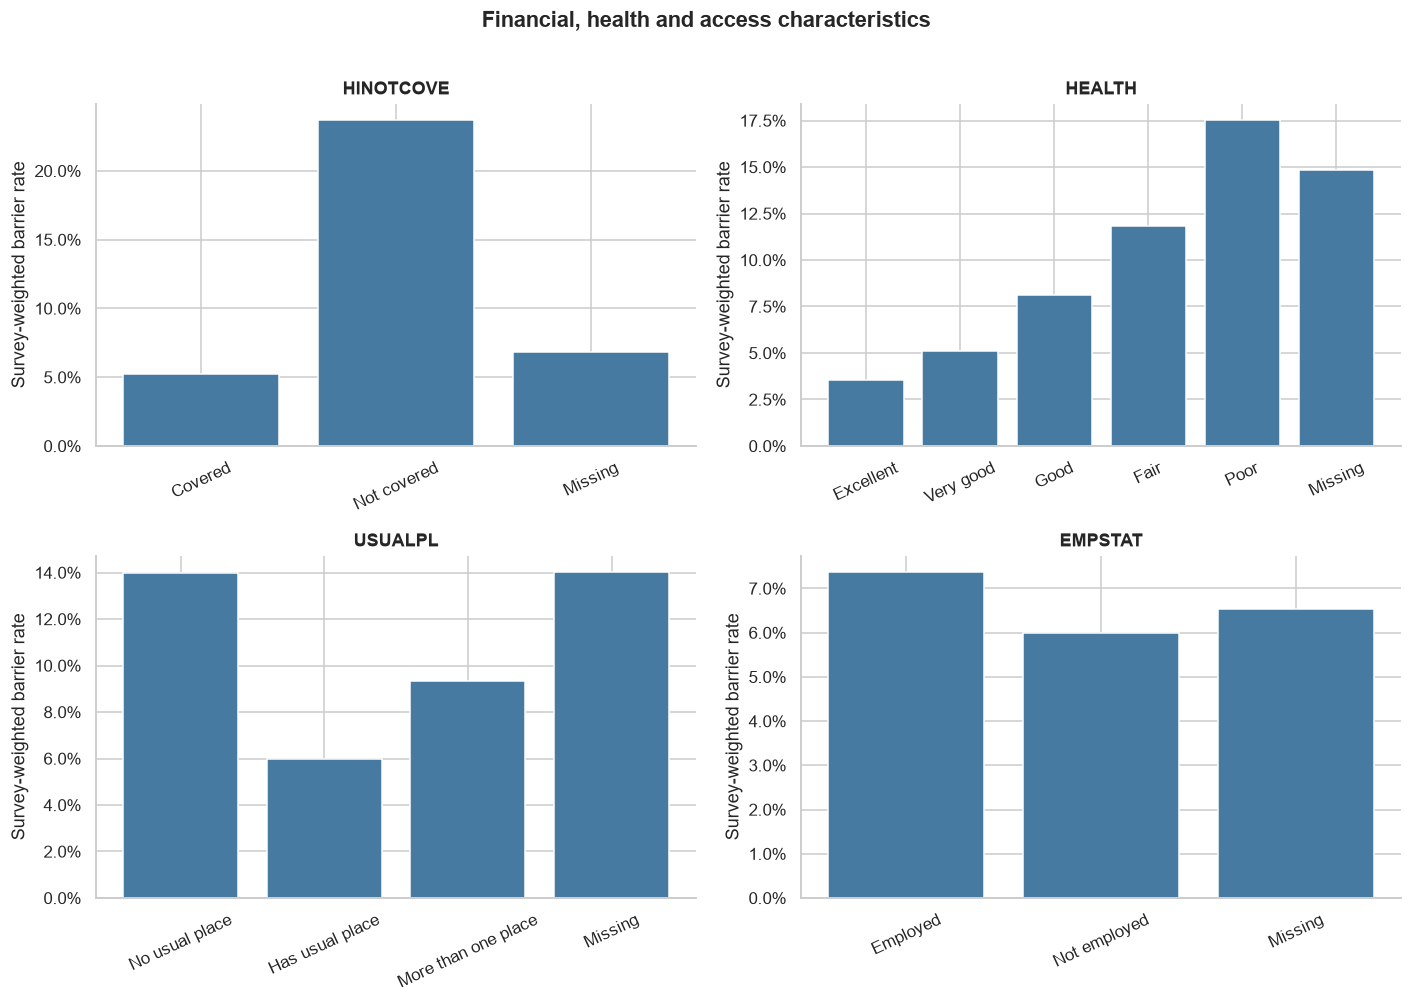

,label,n,positive_cases,weighted_rate
0,Covered,57166,2878,0.0523
1,Not covered,4303,1023,0.2371
2,Missing,161,10,0.0680


**Interpretation:** The weighted barrier rate is **23.7% without coverage** and **5.2% with coverage**. Insurance is therefore a sensible baseline, but covered adults still report barriers. The full model tests whether other information helps distinguish people within each coverage group. Health and usual-care patterns are reasons to test combined information, rather than causal explanations.

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, column in zip(axes.flat, ['HINOTCOVE', 'HEALTH', 'USUALPL', 'EMPSTAT']):
    rates = weighted_rate_by(development, column)
    ax.bar(rates['label'], rates['weighted_rate'], color='#467AA0')
    ax.set(title=column, ylabel='Survey-weighted barrier rate')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis='x', rotation=25)
plt.suptitle('Financial, health and access characteristics', y=1.01, weight='bold')
plt.tight_layout(); plt.show()
insurance_rates = weighted_rate_by(development, 'HINOTCOVE')
display(insurance_rates[['label', 'n', 'positive_cases', 'weighted_rate']])
covered_rate = insurance_rates.loc[insurance_rates['HINOTCOVE'].eq(1), 'weighted_rate'].iloc[0]
uncovered_rate = insurance_rates.loc[insurance_rates['HINOTCOVE'].eq(2), 'weighted_rate'].iloc[0]
display(Markdown(f'**Interpretation:** The weighted barrier rate is **{uncovered_rate:.1%} without coverage** '
                 f'and **{covered_rate:.1%} with coverage**. Insurance is therefore a sensible baseline, '
                 'but covered adults still report barriers. The full model tests whether other information '
                 'helps distinguish people within each coverage group. Health and usual-care patterns '
                 'are reasons to test combined information, rather than causal explanations.'))

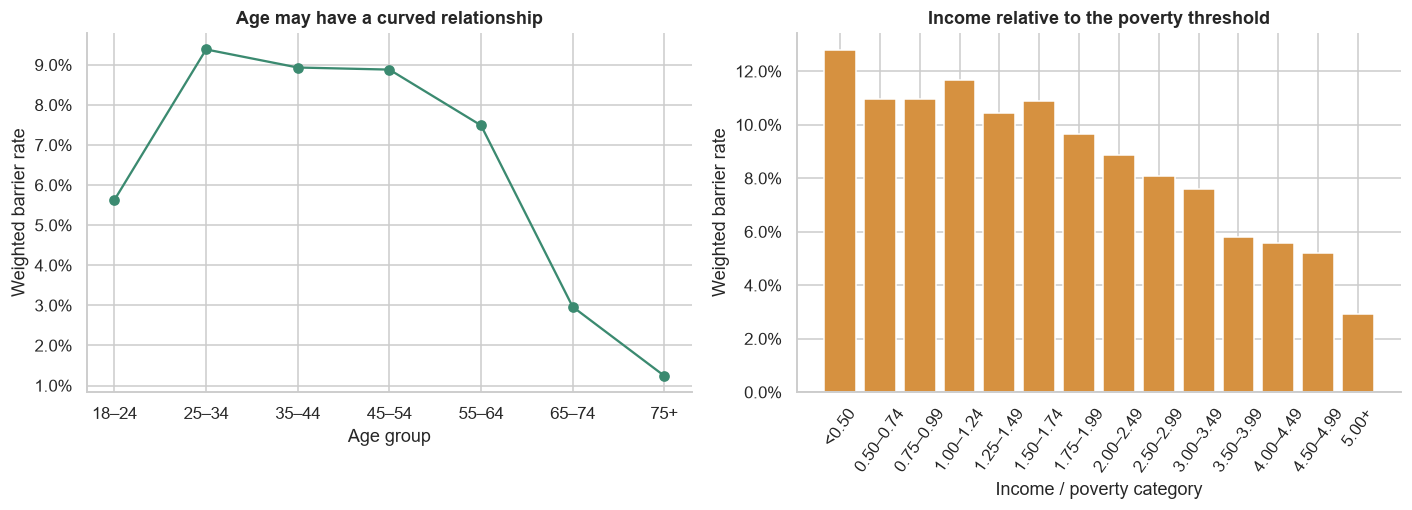

In [7]:
age_data = development.copy()
age_data['AGE_GROUP'] = pd.cut(age_data['AGE'], [17, 24, 34, 44, 54, 64, 74, np.inf],
                               labels=['18–24', '25–34', '35–44', '45–54', '55–64', '65–74', '75+'])
age_rates = age_data.groupby('AGE_GROUP', observed=True).apply(
    lambda g: np.average(g['target'], weights=g['SAMPWEIGHT']), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(age_rates.index.astype(str), age_rates.values, marker='o', color='#3B8A70')
axes[0].set(title='Age may have a curved relationship', xlabel='Age group', ylabel='Weighted barrier rate')
pov_rates = weighted_rate_by(development, 'POVERTY')
axes[1].bar(pov_rates['label'], pov_rates['weighted_rate'], color='#D69140')
axes[1].set(title='Income relative to the poverty threshold', xlabel='Income / poverty category',
            ylabel='Weighted barrier rate')
axes[1].tick_params(axis='x', rotation=55)
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

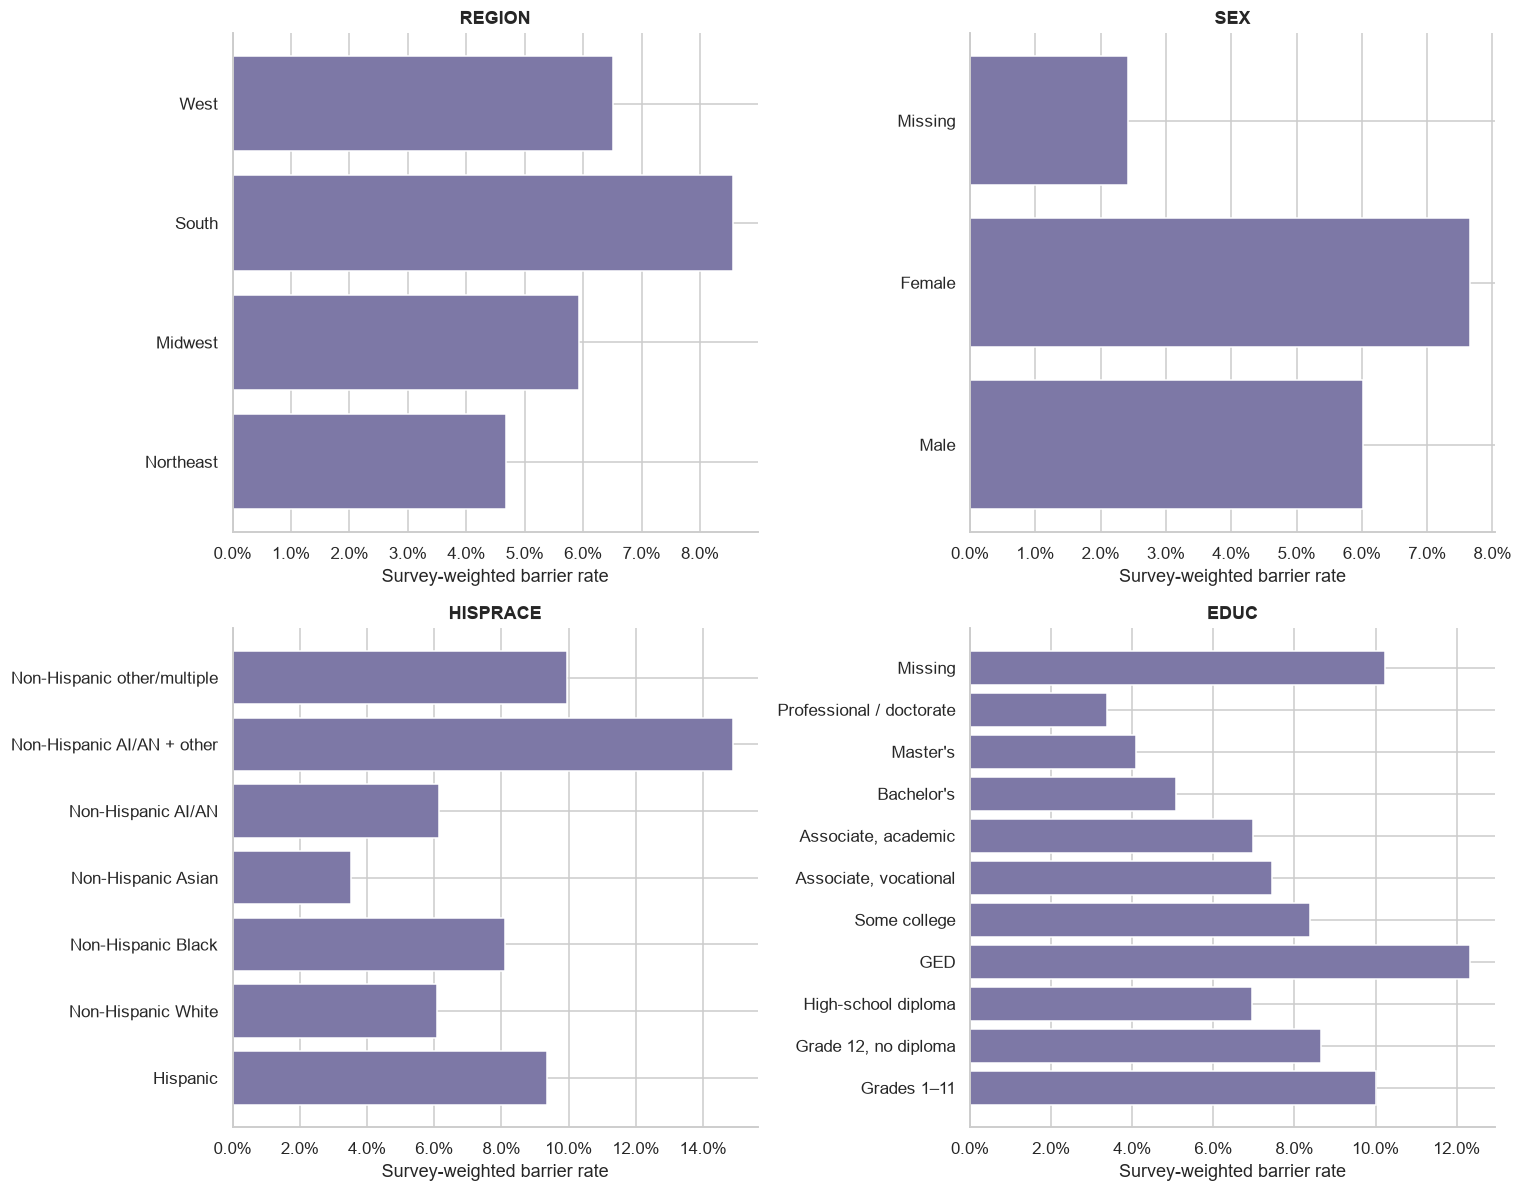

**How we use these charts.** A separate rate for one characteristic does not show what happens after accounting for all the others. We retain the proposed features and let validation assess their combined usefulness. Small demographic groups need cautious interpretation. Race/ethnicity and sex are included as observed descriptors in this research specification; provider use would require a justified policy and checks that prioritisation does not systematically miss groups.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, column in zip(axes.flat, ['REGION', 'SEX', 'HISPRACE', 'EDUC']):
    rates = weighted_rate_by(development, column)
    ax.barh(rates['label'], rates['weighted_rate'], color='#7D78A6')
    ax.set(title=column, xlabel='Survey-weighted barrier rate')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation:** A separate rate for one characteristic does not show '
                 'what happens after accounting for all the others. We retain the proposed features '
                 'and let validation assess their combined usefulness. Small demographic groups need '
                 'cautious interpretation. Race/ethnicity and sex are included as observed descriptors '
                 'in this research specification; provider use would require a justified policy and '
                 'checks that prioritisation does not systematically miss groups.'))

## Part 5: Hypotheses and Transformations
### Feature selection follows the decision, rather than the easiest correlations

| Input | Business reason to test it |
|---|---|
| `HINOTCOVE` | Coverage may reduce financial exposure, but coverage alone cannot describe all affordability problems |
| `POVERTY` | Income relative to family needs gives information about financial resources |
| `HEALTH` | Self-rated health may distinguish adults with different care needs and financial exposure |
| `USUALPL` | A usual place for care may capture differences in access and care navigation |
| `EMPSTAT` | Employment status may relate to financial circumstances and coverage; not employed does not necessarily mean unemployed |
| `AGE` | Life stage, health needs and coverage arrangements may vary across adulthood |
| `EDUC` | May provide additional socioeconomic information; it does not directly measure financial literacy |
| `REGION` | Regional differences may add information; broad regions do not identify a particular clinic's market |
| `SEX` | May help describe observed differences and assess who the model identifies |
| `HISPRACE` | May capture observed disparities and support subgroup checks; it is not a biological or causal explanation |

**What we exclude and why.** `YBARCARE` and its recoded target would reveal the answer. Person IDs identify respondents rather than need. Survey weights, strata, PSU and sample flags describe how records were sampled. `YEAR` defines the split; we exclude it so the model cannot use year labels as a shortcut. We do not add other unmet-care or delayed-care answers that could simply repeat the target.

**Categorical representation.** The nine survey codes are treated as labels. An education code of 400 does not mean twice the education of code 200. **One-hot encoding** creates a separate Yes/No column for each category. Unknown categories in later data are accepted without relearning the column list. Missing answers get a fixed category; median-age imputation is learned from training rows only.

**Nonlinear age and interactions.** The age chart suggests a curve. A spline can represent age curves in logistic regression. This revision focuses on forests and tests ordered representations of poverty, education and health. A random forest can split age at different values and combine insurance, poverty and health through successive branches, so we do not add every possible pair or an age-squared term to the forest. Squaring a nonnegative age preserves its order and adds little to a tree's possible splits. Avoiding hundreds of manual combinations also keeps the feature set understandable.

**Scaling.** Trees do not need standardised inputs to find their splits. The retained preprocessing helper can standardise age for logistic regression; forests do not require it. For descriptive clustering, age is standardised so its units do not overwhelm category differences.

In [9]:
def make_preprocessor(age_mode='raw', columns=None):
    cats = CATEGORICAL if columns is None else [c for c in columns if c != 'AGE']
    parts = []
    if columns is None or 'AGE' in columns:
        age_steps = [('impute', SimpleImputer(strategy='median'))]
        if age_mode == 'quadratic':
            age_steps += [('square', PolynomialFeatures(degree=2, include_bias=False)),
                          ('scale', StandardScaler())]
        elif age_mode == 'spline':
            age_steps += [('spline', SplineTransformer(n_knots=5, degree=3, include_bias=False)),
                          ('scale', StandardScaler())]
        elif age_mode == 'scaled':
            age_steps += [('scale', StandardScaler())]
        parts.append(('age', Pipeline(age_steps), ['AGE']))
    if cats:
        categorical_steps = Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value=-1)),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ])
        parts.append(('category', categorical_steps, cats))
    return ColumnTransformer(parts, remainder='drop')

def model_pipeline(model, age_mode='raw', columns=None):
    return Pipeline([('prepare', make_preprocessor(age_mode, columns)), ('model', model)])

def rank_indices(scores):
    scores = np.asarray(scores, dtype=float)
    if not np.isfinite(scores).all():
        raise ValueError('All scores must be finite.')
    # Fixed random tie order is independent of targets and person IDs.
    ties = np.random.default_rng(RANDOM_STATE).permutation(len(scores))
    return np.lexsort((ties, -scores))

def select_top_k(scores, k):
    k = int(k)
    if not 0 <= k <= len(scores):
        raise ValueError('K must be between 0 and the number scored.')
    selected = np.zeros(len(scores), dtype=bool)
    selected[rank_indices(scores)[:k]] = True
    return selected

def capacity_metrics(y_true, scores, fraction):
    y = np.asarray(y_true, dtype=int)
    k = int(np.ceil(fraction * len(y)))
    selected = select_top_k(scores, k)
    tp = int(y[selected].sum())
    fp = k - tp
    fn = int(y.sum()) - tp
    tn = len(y) - tp - fp - fn
    precision = tp / k if k else 0.0
    recall = tp / y.sum() if y.sum() else 0.0
    return {'capacity': fraction, 'contacts': k, 'cases_found': tp, 'false_positives': fp,
            'missed_cases': fn, 'true_negatives': tn, 'precision': precision,
            'recall': recall, 'lift': precision / y.mean() if y.mean() else np.nan}

def mean_capacity_recall(y_true, scores):
    return float(np.mean([capacity_metrics(y_true, scores, q)['recall']
                          for q in SELECTION_CAPACITIES]))

capacity_scorer = make_scorer(mean_capacity_recall, response_method='predict_proba')
scoring = {'mean_capacity_recall': capacity_scorer, 'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}

def overall_metrics(y, scores):
    return {'AP': average_precision_score(y, scores), 'ROC_AUC': roc_auc_score(y, scores),
            'Brier': brier_score_loss(y, scores)}

def table_at_capacities(y, score_dictionary, capacities=CAPACITIES):
    return pd.DataFrame([{'method': name, **capacity_metrics(y, scores, q)}
                         for name, scores in score_dictionary.items() for q in capacities])

## Part 6: Recall-Focused Modelling and Model Selection

### Changes tested
| Representation | What changes | Business rationale |
|---|---|---|
| One-hot reference | Separate indicators for each survey category | Preserves the original approach without assuming nominal codes have a numeric meaning |
| Ordered | Income-to-poverty, education and health are represented in their documented order; other categories remain one-hot | Lets a tree group adjacent levels, instead of needing several separate splits to describe broader financial or health patterns |
| Hybrid | Retains both ordered values and category indicators for these three inputs | Tests whether broad gradients and particular categories provide complementary information |

The ordered values are ranks, not exact income, years of schooling, or distances between health states. GED and high-school diploma share an attainment rank, as do the two associate-degree categories. No ordering is imposed on region, race/ethnicity or insurance categories. Training-fold median imputation and missingness indicators handle missing ordered inputs. No target-derived feature or information from 2025 is added.

Trees can learn interactions without manually multiplying all the inputs. We test eight forest settings per representation, varying leaf size, depth, feature sampling and positive-class weighting. Stronger class weighting is not assumed to be better. All forests use 150 trees to make the exercise reproducible and manageable.

### How the revised model and cutoff are chosen
1. **2023 five-fold CV** compares forest settings using average precision (AP). This first screens ranking quality without choosing an operating cutoff from the CV assessment folds.
2. The best **two settings per representation**, plus the original forest reference, are evaluated on **2024**. Each receives a cutoff chosen to maximise **F2** on 2024. F2 gives recall greater emphasis than precision; it is an explicit analytical preference for this revision, not an estimated financial cost ratio.
3. The model-and-cutoff combination with the highest validation F2 is selected. Exact ties favour higher recall, then fewer false positives and a simpler representation. The selected cutoff is fixed before 2025 is opened.
4. A **conservative alternative cutoff** is also frozen. On 2024 it finds as many cases as possible while allowing no more false positives than the original forest's illustrative 10% list. This is an experimental comparison anchor, not an established provider budget. Its 2025 false-positive count is not guaranteed to stay within the earlier sample's limit.

We also compare both forests at the same contact capacities. This distinguishes better ranking from simply making a longer list. 2024 scores are model-selection results and can be optimistic; 2025 has also been examined previously in the project, so further independent confirmation remains necessary.

In [10]:
ORDER_MAPS = {
    'POVERTY': {11: 1, 12: 2, 13: 3, 21: 4, 22: 5, 23: 6, 24: 7,
                31: 8, 32: 9, 33: 10, 34: 11, 35: 12, 36: 13, 37: 14},
    'EDUC': {103: 0, 116: 1, 201: 2, 202: 2, 301: 3, 302: 4, 303: 4,
             400: 5, 510: 6, 520: 7},
    'HEALTH': {1: 1, 2: 2, 3: 3, 4: 4, 5: 5}
}
ORDERED = ['POVERTY', 'EDUC', 'HEALTH']
for col in ORDERED:
    # Check development codes against the documented map; no evaluation read.
    assert set(development[col].dropna()).issubset(ORDER_MAPS[col])

def revised_pipeline(representation, parameters):
    if representation == 'One-hot':
        return model_pipeline(RandomForestClassifier(n_estimators=150, n_jobs=1,
            random_state=RANDOM_STATE, **parameters))
    numeric = ['AGE'] + ORDERED
    categorical = CATEGORICAL if representation == 'Hybrid' else [c for c in CATEGORICAL if c not in ORDERED]
    mapping = FunctionTransformer(pd.DataFrame.replace,
        kw_args={'to_replace': ORDER_MAPS}, validate=False, feature_names_out='one-to-one')
    preprocess = ColumnTransformer([
        ('ordered_numeric', Pipeline([('rank_codes', mapping),
            ('impute', SimpleImputer(strategy='median', add_indicator=True))]), numeric),
        ('categories', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value=-1)),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)
    ])
    # This is a fixed codebook mapping, not an estimate learned from outcomes.
    return Pipeline([('prepare', preprocess),
        ('model', RandomForestClassifier(n_estimators=150, n_jobs=1,
                                         random_state=RANDOM_STATE, **parameters))])

FOREST_SETTINGS = [
    {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'},
    {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 0.7, 'class_weight': None},
    {'max_depth': 12, 'min_samples_leaf': 40, 'max_features': 0.7, 'class_weight': None},
    {'max_depth': None, 'min_samples_leaf': 80, 'max_features': 1.0, 'class_weight': None},
    {'max_depth': None, 'min_samples_leaf': 8, 'max_features': 0.7, 'class_weight': 'balanced_subsample'},
    {'max_depth': 16, 'min_samples_leaf': 20, 'max_features': 1.0, 'class_weight': {0: 1, 1: 3}},
    {'max_depth': None, 'min_samples_leaf': 60, 'max_features': 0.7, 'class_weight': {0: 1, 1: 3}},
    {'max_depth': 8, 'min_samples_leaf': 80, 'max_features': 1.0, 'class_weight': 'balanced_subsample'}
]

def threshold_table(y_true, scores):
    y, p = np.asarray(y_true, dtype=int), np.asarray(scores, dtype=float)
    order = np.argsort(-p, kind='stable')
    ordered_p, ordered_y = p[order], y[order]
    end = np.r_[np.flatnonzero(ordered_p[:-1] != ordered_p[1:]), len(p)-1]
    tp = np.cumsum(ordered_y)[end]
    contacts = end + 1
    fp, fn = contacts - tp, y.sum() - tp
    precision = np.divide(tp, contacts, out=np.zeros(len(tp), dtype=float), where=contacts > 0)
    recall = tp / y.sum()
    f2 = np.divide(5*tp, 5*tp + 4*fn + fp, out=np.zeros(len(tp), dtype=float),
                   where=(5*tp + 4*fn + fp) > 0)
    return pd.DataFrame({'cutoff': ordered_p[end], 'cases_found': tp, 'false_positives': fp,
        'missed_cases': fn, 'contacts': contacts, 'precision': precision, 'recall': recall, 'F2': f2})

def choose_f2(y, scores):
    return threshold_table(y, scores).sort_values(
        ['F2', 'recall', 'false_positives', 'cutoff'], ascending=[False, False, True, False]).iloc[0]

def binary_metrics(y_true, selected):
    y, selected = np.asarray(y_true, dtype=int), np.asarray(selected, dtype=bool)
    tp = int(y[selected].sum()); fp = int(selected.sum())-tp
    fn = int(y.sum())-tp; tn = int((1-y).sum())-fp
    return {'cases_found': tp, 'missed_cases': fn, 'false_positives': fp,
            'true_negatives': tn, 'flagged': int(selected.sum()),
            'precision': tp/(tp+fp) if tp+fp else 0,
            'recall': tp/(tp+fn) if tp+fn else 0,
            'F2': 5*tp/(5*tp + 4*fn + fp) if 5*tp+4*fn+fp else 0}

In [ ]:
assert not TEST_OPENED
original_validation_model = revised_pipeline('One-hot', FOREST_SETTINGS[0])
fit_development(original_validation_model, X_train, y_train, initial_train, 'Original forest reference: 2023')
original_validation_scores = original_validation_model.predict_proba(X_validation)[:, 1]
original_f2_choice = choose_f2(y_validation, original_validation_scores)
original_fixed_cutoff = float(original_f2_choice['cutoff'])

representation_searches, candidate_models, candidate_scores, rows = {}, {}, {}, []
candidate_models['Original forest reference'] = original_validation_model
candidate_scores['Original forest reference'] = original_validation_scores
rows.append({'candidate': 'Original forest reference', 'representation': 'One-hot',
              'complexity': 0, 'settings': FOREST_SETTINGS[0],
              'CV_AP': np.nan, 'validation_AP': average_precision_score(y_validation, original_validation_scores),
              **original_f2_choice.to_dict()})

for representation in ['One-hot', 'Ordered', 'Hybrid']:
    estimator = revised_pipeline(representation, FOREST_SETTINGS[0])
    grid = [{f'model__{key}': [value] for key, value in setting.items()} for setting in FOREST_SETTINGS]
    search = GridSearchCV(estimator, grid, scoring={'AP': 'average_precision', 'AUC': 'roc_auc'},
                          refit='AP', cv=cv, n_jobs=N_JOBS, error_score='raise')
    started = time.perf_counter()
    fit_development(search, X_train, y_train, initial_train, representation + ': 2023 five-fold search')
    representation_searches[representation] = search
    results = pd.DataFrame(search.cv_results_).sort_values('mean_test_AP', ascending=False)
    for number, (_, result) in enumerate(results.head(2).iterrows(), 1):
        name = f'{representation} finalist {number}'
        model = clone(search.estimator).set_params(**result['params'])
        fit_development(model, X_train, y_train, initial_train, name + ': 2023 fit')
        scores = model.predict_proba(X_validation)[:, 1]
        choice = choose_f2(y_validation, scores)
        candidate_models[name], candidate_scores[name] = model, scores
        rows.append({'candidate': name, 'representation': representation,
                      'complexity': ['One-hot', 'Ordered', 'Hybrid'].index(representation) + 1,
                      'settings': result['params'], 'CV_AP': result['mean_test_AP'],
                      'validation_AP': average_precision_score(y_validation, scores), **choice.to_dict()})
    print(f'Completed {representation}: {time.perf_counter()-started:.1f}s', flush=True)

recall_comparison = pd.DataFrame(rows).sort_values(
    ['F2', 'recall', 'false_positives', 'complexity'], ascending=[False, False, True, True]).reset_index(drop=True)
selected_forest_name = recall_comparison.iloc[0]['candidate']
selected_validation_model = candidate_models[selected_forest_name]
selected_validation_scores = candidate_scores[selected_forest_name]
fixed_recall_cutoff = float(recall_comparison.iloc[0]['cutoff'])

old_val_selection = select_top_k(original_validation_scores, int(np.ceil(0.10 * len(validation))))
original_validation_point = binary_metrics(y_validation, old_val_selection)
conservative_candidates = threshold_table(y_validation, selected_validation_scores)
conservative_candidates = conservative_candidates.loc[
    conservative_candidates['false_positives'] <= original_validation_point['false_positives']]
conservative_choice = conservative_candidates.sort_values(
    ['cases_found', 'false_positives', 'cutoff'], ascending=[False, True, False]).iloc[0]
fixed_conservative_cutoff = float(conservative_choice['cutoff'])
display(recall_comparison[['candidate', 'CV_AP', 'validation_AP', 'cutoff',
    'recall', 'precision', 'F2', 'missed_cases', 'false_positives']])
print('Selected forest:', selected_forest_name)
print('Recall-first cutoff:', repr(fixed_recall_cutoff))
print('Conservative cutoff:', repr(fixed_conservative_cutoff))

Completed One-hot: 85.1s
Completed Ordered: 64.0s


In [ ]:
insurance_validation_model = model_pipeline(LogisticRegression(C=1.0, max_iter=2500), columns=['HINOTCOVE'])
fit_development(insurance_validation_model, X_train, y_train, initial_train, 'Insurance baseline: 2023')
constant_validation_model = DummyClassifier(strategy='prior')
fit_development(constant_validation_model, X_train, y_train, initial_train, 'Constant baseline: 2023')
validation_score_dictionary = {'Random forest': selected_validation_scores,
    'Original forest': original_validation_scores,
    'Insurance only': insurance_validation_model.predict_proba(X_validation)[:, 1]}
validation_capacity_table = table_at_capacities(y_validation, validation_score_dictionary)
validation_operating = pd.DataFrame([
    {'procedure': 'Original forest: illustrative 10% list', **original_validation_point},
    {'procedure': 'Original forest: F2 cutoff', **binary_metrics(y_validation, original_validation_scores >= original_fixed_cutoff)},
    {'procedure': 'Revised forest: F2 cutoff', **binary_metrics(y_validation, selected_validation_scores >= fixed_recall_cutoff)},
    {'procedure': 'Revised forest: conservative cutoff', **binary_metrics(y_validation, selected_validation_scores >= fixed_conservative_cutoff)}])
display(validation_operating)
display(validation_capacity_table[['method', 'capacity', 'contacts', 'cases_found', 'missed_cases',
                                    'false_positives', 'recall', 'precision', 'lift']])
display(Markdown('**Interpretation.** The F2 rows show the effect of giving missed cases greater emphasis. '
    'Comparing the two F2 rows is more informative about the changed forest than comparing a short '
    'list with a much longer list. The conservative row tests a smaller change in workload. The '
    'same-capacity table remains the direct check of ranking gains. None of these validation '
    'results guarantees the same trade-off in a later year.'))

,procedure,cases_found,missed_cases,false_positives,true_negatives,flagged,precision,recall,F2
0,Original forest: illustrative 10% list,780,1415,2456,27703,3236,0.2410,0.3554,0.3246
1,Original forest: F2 cutoff,1490,705,8483,21676,9973,0.1494,0.6788,0.3973
2,Revised forest: F2 cutoff,1486,709,8272,21887,9758,0.1523,0.6770,0.4008
3,Revised forest: conservative cutoff,758,1437,2453,27706,3211,0.2361,0.3453,0.3161


,method,capacity,contacts,cases_found,missed_cases,false_positives,recall,precision,lift
0,Random forest,0.0500,1618,464,1731,1154,0.2114,0.2868,4.2270
1,Random forest,0.1000,3236,761,1434,2475,0.3467,0.2352,3.4663
2,Random forest,0.2000,6471,1158,1037,5313,0.5276,0.1790,2.6377
3,Random forest,0.3000,9707,1478,717,8229,0.6733,0.1523,2.2443
4,Random forest,0.4000,12942,1661,534,11281,0.7567,0.1283,1.8917
5,Random forest,0.5000,16177,1835,360,14342,0.8360,0.1134,1.6720
6,Original forest,0.0500,1618,462,1733,1156,0.2105,0.2855,4.2088
7,Original forest,0.1000,3236,780,1415,2456,0.3554,0.2410,3.5529
8,Original forest,0.2000,6471,1180,1015,5291,0.5376,0.1824,2.6878
9,Original forest,0.3000,9707,1461,734,8246,0.6656,0.1505,2.2185


**Interpretation.** The F2 rows show the effect of giving missed cases greater emphasis. Comparing the two F2 rows is more informative about the changed forest than comparing a short list with a much longer list. The conservative row tests a smaller change in workload. The same-capacity table remains the direct check of ranking gains. None of these validation results guarantees the same trade-off in a later year.

### Selected procedure and what changed
The 2024 selection rule chose **Hybrid finalist 1**, using the **Hybrid** representation. Its forest has **150 trees**, a minimum of **20 adults per leaf**, feature sampling set to **sqrt**, and class weighting set to **balanced_subsample**. The selected depth limit is **None** (`None` means no fixed depth limit, while leaf-size constraints still apply).

The **recall-first cutoff is 0.432294** and the **conservative cutoff is 0.645514**. Calculations use the full stored values, not these rounded display values. Both were chosen using 2024 only, before the final 2023–2024 refit and 2025 evaluation. A cutoff is a boundary on a model score; it is neither a contact percentage nor a guaranteed individual probability.

The original forest is retained as a control, including its own F2 cutoff. If it performs similarly, we should attribute most of the change to the operating rule rather than claim that extra feature engineering solved the problem. Cross-validation screens ranking quality; validation then selects the complete model-and-cutoff procedure. The validation F2 advantage is a selection result, not an independent estimate of future performance.


### Cutoff selection: business rationale and analytical process

Our business goal is to identify adults who may need affordability-related support, while using limited outreach resources sensibly. **For this project, missing a reported case is considered worse than making an unnecessary initial contact.** A missed adult receives no proactive invitation through this model-led outreach route. An unnecessary contact uses staff time and may inconvenience the recipient, but a brief needs check can establish whether further support is wanted.

| Decision error | Meaning in this project | Business implication |
|---|---|---|
| False negative: missed case | An adult reported being unable to obtain needed medical care because of cost, but is not flagged | A potential opportunity to offer affordability support is missed |
| False positive: unnecessary flag | An adult is flagged but did not report this specific barrier | Additional contact and screening workload, with no confirmed need for this particular support |

The model's target describes the **previous 12 months**. A flag does not establish a current support need or financial assistance eligibility. The proposed first action is a short needs check; more detailed counselling follows the person's confirmed circumstances and willingness to receive help. This makes the consequence of a false positive different from automatically awarding assistance.

#### Step 1: Express the priority in a selection measure

**Recall** is the share of reported cases we find. **Precision** is the share of flagged adults who reported the barrier. We use **F2**, a combined measure that gives recall greater emphasis while still penalising unnecessary flags. Higher F2 is better under this chosen preference.

$$
F_2 = \frac{5\times\text{Precision}\times\text{Recall}}
{4\times\text{Precision}+\text{Recall}}
=\frac{5TP}{5TP+4FN+FP}
$$

Here, TP means cases found, FN means missed cases, and FP means false positives. The coefficient on FN is part of the F2 formula; **it does not establish that a missed case costs four times as much money as a false positive**. Choosing F2 is a transparent project assumption reflecting our business priority. Actual outreach costs and the value of reaching a case are unavailable, so we cannot claim a financially optimal cutoff. Maximising recall alone would flag everyone; F2 keeps follow-up workload relevant.

#### Step 2: Compare cutoffs using 2024 validation data

The candidate forests were trained on **2023** after the cross-validation screen. For each finalist, the code above tests **every distinct score cutoff on 2024**, calculates cases found, missed cases, false positives, recall, precision and F2, and keeps the cutoff with the highest F2. Exact cutoff ties in F2 favour higher recall, then fewer false positives, then the higher cutoff. The candidate-and-cutoff comparison then favours the highest validation F2, with the tie rules stated earlier.

The following cells unpack that existing selection. The first table shows a few easy-to-read alternatives for the selected forest; these examples are not the search grid. The second table shows the five highest-F2 cutoffs from the full validation search. All flags use **score >= cutoff**, including tied scores. Calculations retain the full cutoff value even when the table displays fewer decimals.

In [ ]:
# Format a display copy so the underlying scores and cutoffs retain full precision.
def show_cutoff_table(table, formats, caption):
    formatted = table.copy().reset_index(drop=True)
    for column, pattern in formats.items():
        if column in formatted:
            formatted[column] = formatted[column].map(pattern.format)
    display(Markdown('**' + caption + '**'))
    display(formatted)

# Recheck the existing choice using only the 2024 validation scores.
assert not TEST_OPENED
assert set(validation['YEAR']) == {2024}
cutoff_search_review = threshold_table(y_validation, selected_validation_scores)
cutoff_search_ranked = cutoff_search_review.sort_values(
    ['F2', 'recall', 'false_positives', 'cutoff'],
    ascending=[False, False, True, False]).reset_index(drop=True)
assert float(cutoff_search_ranked.iloc[0]['cutoff']) == fixed_recall_cutoff

print(f'Validation adults: {len(y_validation):,}; reported cases: {int(y_validation.sum()):,}')
print(f'Distinct score cutoffs compared: {len(cutoff_search_ranked):,}')
print('Selected full-precision cutoff:', repr(fixed_recall_cutoff))

# These illustrative rows explain the trade-off; selection used all cutoffs above.
cutoff_examples = [
    ('Lower cutoff example', 0.30),
    ('Lower cutoff example', 0.40),
    ('SELECTED: highest validation F2', fixed_recall_cutoff),
    ('Common default for comparison', 0.50),
    ('Higher cutoff example', 0.60),
    ('Conservative FP-constrained alternative', fixed_conservative_cutoff),
]
cutoff_review_rows = []
for rule, cutoff in cutoff_examples:
    measures = binary_metrics(y_validation, selected_validation_scores >= cutoff)
    cutoff_review_rows.append({'rule': rule, 'cutoff': cutoff, **measures,
                              'share_flagged': measures['flagged'] / len(y_validation)})
validation_cutoff_review = pd.DataFrame(cutoff_review_rows).sort_values('cutoff')
review_columns = ['rule', 'cutoff', 'cases_found', 'missed_cases', 'false_positives',
                  'flagged', 'share_flagged', 'recall', 'precision', 'F2']
review_formats = {'cutoff': '{:.6f}', 'share_flagged': '{:.1%}',
                  'recall': '{:.1%}', 'precision': '{:.1%}', 'F2': '{:.6f}'}
review_formats.update({c: '{:,.0f}' for c in
                      ['cases_found', 'missed_cases', 'false_positives', 'flagged']})
show_cutoff_table(validation_cutoff_review[review_columns], review_formats,
                  '2024 validation: selected cutoff and alternatives')

top_cutoffs_review = cutoff_search_ranked.head(5).copy()
top_cutoffs_review['rank'] = np.arange(1, len(top_cutoffs_review) + 1)
show_cutoff_table(top_cutoffs_review[['rank', 'cutoff', 'cases_found', 'missed_cases',
        'false_positives', 'contacts', 'recall', 'precision', 'F2']], {
            'cutoff': '{:.9f}', 'recall': '{:.2%}', 'precision': '{:.2%}',
            'F2': '{:.9f}', 'cases_found': '{:,.0f}', 'missed_cases': '{:,.0f}',
            'false_positives': '{:,.0f}', 'contacts': '{:,.0f}'},
        '2024 validation: five highest-F2 cutoffs')

Validation adults: 32,354; reported cases: 2,195
Distinct score cutoffs compared: 29,015
Selected full-precision cutoff: 0.43229443150184815


**2024 validation: selected cutoff and alternatives**

,rule,cutoff,cases_found,missed_cases,false_positives,flagged,share_flagged,recall,precision,F2
0,Lower cutoff example,0.300000,"1,826",369,"14,123","15,949",49.3%,83.2%,11.4%,0.369202
1,Lower cutoff example,0.400000,"1,560",635,"9,602","11,162",34.5%,71.1%,14.0%,0.391134
2,SELECTED: highest validation F2,0.432294,"1,486",709,"8,272","9,758",30.2%,67.7%,15.2%,0.400798
3,Common default for comparison,0.500000,"1,238",957,"5,934","7,172",22.2%,56.4%,17.3%,0.388039
4,Higher cutoff example,0.600000,892,"1,303","3,306","4,198",13.0%,40.6%,21.2%,0.343658
5,Conservative FP-constrained alternative,0.645514,758,"1,437","2,453","3,211",9.9%,34.5%,23.6%,0.316070


**2024 validation: five highest-F2 cutoffs**

,rank,cutoff,cases_found,missed_cases,false_positives,contacts,recall,precision,F2
0,1,0.432294432,"1,486",709,"8,272","9,758",67.70%,15.23%,0.400798360
1,2,0.432252329,"1,486",709,"8,273","9,759",67.70%,15.23%,0.400776741
2,3,0.431280026,"1,489",706,"8,308","9,797",67.84%,15.20%,0.400764386
3,4,0.432224187,"1,486",709,"8,274","9,760",67.70%,15.23%,0.400755124
4,5,0.431269589,"1,489",706,"8,309","9,798",67.84%,15.20%,0.400742814


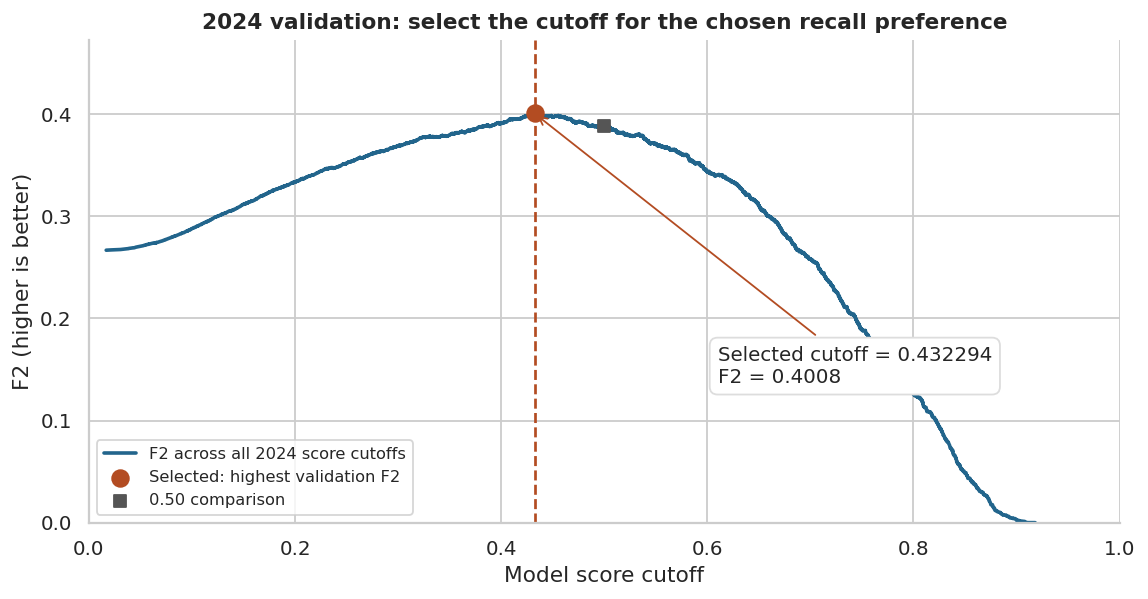

In [ ]:
# Show where the chosen cutoff sits on the full validation F2 curve.
curve_review = cutoff_search_review.sort_values('cutoff')
chosen_review = cutoff_search_ranked.iloc[0]
default_review = validation_cutoff_review.loc[
    validation_cutoff_review['rule'].eq('Common default for comparison')].iloc[0]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(curve_review['cutoff'], curve_review['F2'], color='#22658c',
        linewidth=2, label='F2 across all 2024 score cutoffs')
ax.axvline(fixed_recall_cutoff, color='#b34c22', linestyle='--', linewidth=1.5)
ax.scatter([fixed_recall_cutoff], [chosen_review['F2']], color='#b34c22',
           s=85, zorder=4, label='Selected: highest validation F2')
ax.scatter([0.50], [default_review['F2']], color='#555555', marker='s',
           s=48, zorder=4, label='0.50 comparison')
ax.annotate(f"Selected cutoff = {fixed_recall_cutoff:.6f}\nF2 = {chosen_review['F2']:.4f}",
            xy=(fixed_recall_cutoff, chosen_review['F2']),
            xytext=(0.61, 0.29), textcoords='axes fraction',
            arrowprops={'arrowstyle': '->', 'color': '#b34c22'}, fontsize=11,
            bbox={'boxstyle': 'round,pad=0.4', 'facecolor': 'white', 'edgecolor': '#ddd'})
ax.set(xlim=(0, 1), ylim=(0, max(0.46, float(chosen_review['F2']) * 1.18)),
       xlabel='Model score cutoff', ylabel='F2 (higher is better)',
       title='2024 validation: select the cutoff for the chosen recall preference')
ax.legend(loc='lower left', frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# Translate the measured trade-offs into a business explanation.
selected_review = validation_cutoff_review.loc[
    validation_cutoff_review['rule'].eq('SELECTED: highest validation F2')].iloc[0]
lower_review = validation_cutoff_review.loc[validation_cutoff_review['cutoff'].eq(0.30)].iloc[0]
conservative_review = validation_cutoff_review.loc[
    validation_cutoff_review['rule'].eq('Conservative FP-constrained alternative')].iloc[0]
original_review = binary_metrics(y_validation,
    original_validation_scores >= original_fixed_cutoff)

display(Markdown(
    '#### Step 3: Explain the selected trade-off\n\n'
    f"At **{fixed_recall_cutoff:.6f}**, the selected forest finds "
    f"**{int(selected_review['cases_found']):,} of {int(y_validation.sum()):,} reported cases "
    f"({selected_review['recall']:.1%} recall)**. It misses "
    f"**{int(selected_review['missed_cases']):,}** and produces "
    f"**{int(selected_review['false_positives']):,} false positives**. It flags "
    f"**{int(selected_review['flagged']):,} adults ({selected_review['share_flagged']:.1%})**. "
    'That share is a result of applying the cutoff, rather than an imposed contact quota.\n\n'
    f"Compared with 0.50, the selected cutoff finds "
    f"**{int(selected_review['cases_found'] - default_review['cases_found']):,} additional cases** "
    f"and adds **{int(selected_review['false_positives'] - default_review['false_positives']):,} "
    'false positives**. We accept the additional initial screening workload because the stated '
    'business priority gives greater weight to reaching cases that would otherwise be missed.\n\n'
    f"Reducing the cutoff further to 0.30 finds "
    f"**{int(lower_review['cases_found'] - selected_review['cases_found']):,} more cases**, but adds "
    f"**{int(lower_review['false_positives'] - selected_review['false_positives']):,} false positives**. "
    f"Its F2 is **{lower_review['F2']:.4f}**, below **{selected_review['F2']:.4f}** at the selected "
    'cutoff. Under the chosen F2 preference, this extra workload outweighs the gain in case finding. '
    'A stronger business preference for avoiding misses could justify a different selection rule.\n\n'
    f"The conservative cutoff of **{fixed_conservative_cutoff:.6f}** keeps validation false "
    "positives within the original illustrative 10% list's count, but its recall is only "
    f"**{conservative_review['recall']:.1%}**. We retain it as a workload comparison; the "
    "recall-focused procedure follows the project's stated priority."
))
display(Markdown(
    '**Why this forest wins the candidate comparison.** The original forest at its own '
    f"F2 cutoff has **{int(original_review['missed_cases']):,} missed cases** and "
    f"**{int(original_review['false_positives']):,} false positives** on 2024. The selected hybrid "
    f"forest therefore has **{int(selected_review['missed_cases'] - original_review['missed_cases']):,} "
    f"more misses** and **{int(original_review['false_positives'] - selected_review['false_positives']):,} "
    'fewer false positives** in validation. Its F2 is higher '
    f"(**{selected_review['F2']:.4f} versus {original_review['F2']:.4f}**), so it wins the stated "
    'combined rule. This explicitly shows that the selection balances both errors while '
    'giving recall more emphasis; it does not simply choose the candidate with the fewest misses.'
))

#### Step 3: Explain the selected trade-off

At **0.432294**, the selected forest finds **1,486 of 2,195 reported cases (67.7% recall)**. It misses **709** and produces **8,272 false positives**. It flags **9,758 adults (30.2%)**. That share is a result of applying the cutoff, rather than an imposed contact quota.

Compared with 0.50, the selected cutoff finds **248 additional cases** and adds **2,338 false positives**. We accept the additional initial screening workload because the stated business priority gives greater weight to reaching cases that would otherwise be missed.

Reducing the cutoff further to 0.30 finds **340 more cases**, but adds **5,851 false positives**. Its F2 is **0.3692**, below **0.4008** at the selected cutoff. Under the chosen F2 preference, this extra workload outweighs the gain in case finding. A stronger business preference for avoiding misses could justify a different selection rule.

The conservative cutoff of **0.645514** keeps validation false positives within the original illustrative 10% list's count, but its recall is only **34.5%**. We retain it as a workload comparison; the recall-focused procedure follows the project's stated priority.

**Why this forest wins the candidate comparison.** The original forest at its own F2 cutoff has **705 missed cases** and **8,483 false positives** on 2024. The selected hybrid forest therefore has **4 more misses** and **211 fewer false positives** in validation. Its F2 is higher (**0.4008 versus 0.3973**), so it wins the stated combined rule. This explicitly shows that the selection balances both errors while giving recall more emphasis; it does not simply choose the candidate with the fewest misses.

#### Step 4: Fix the decision before final evaluation

The full-precision cutoff **0.43229443150184815** is fixed from the 2024 search. We then refit the chosen forest on 2023–2024 and apply that same cutoff to 2025. Refitting can shift score levels, so later recall and false positives can differ from validation. The 2025 comparison in Part 9 reports what happened after applying the fixed procedures; those figures are not used to choose or adjust this cutoff.

The large reduction in misses against the earlier illustrative 10% list mainly reflects **allowing a larger outreach list**. Comparing both forests with their own validation-selected F2 cutoffs provides the clearer check of the additional model changes. A provider would still need to confirm that the resulting screening workload is feasible. F2 does not establish a financial return or guarantee fewer false positives in future data.

## Part 7: Model Diagnostics and Business Plausibility
The following diagnostics use the model fitted on 2023 and checked on 2024. A cumulative-gains curve shows what share of cases is found as more adults are contacted. Precision shows the yield per contact; lift compares that yield with random selection. Better models are compared at the same horizontal position. We also inspect precision–recall, score reliability and original-variable importance. 

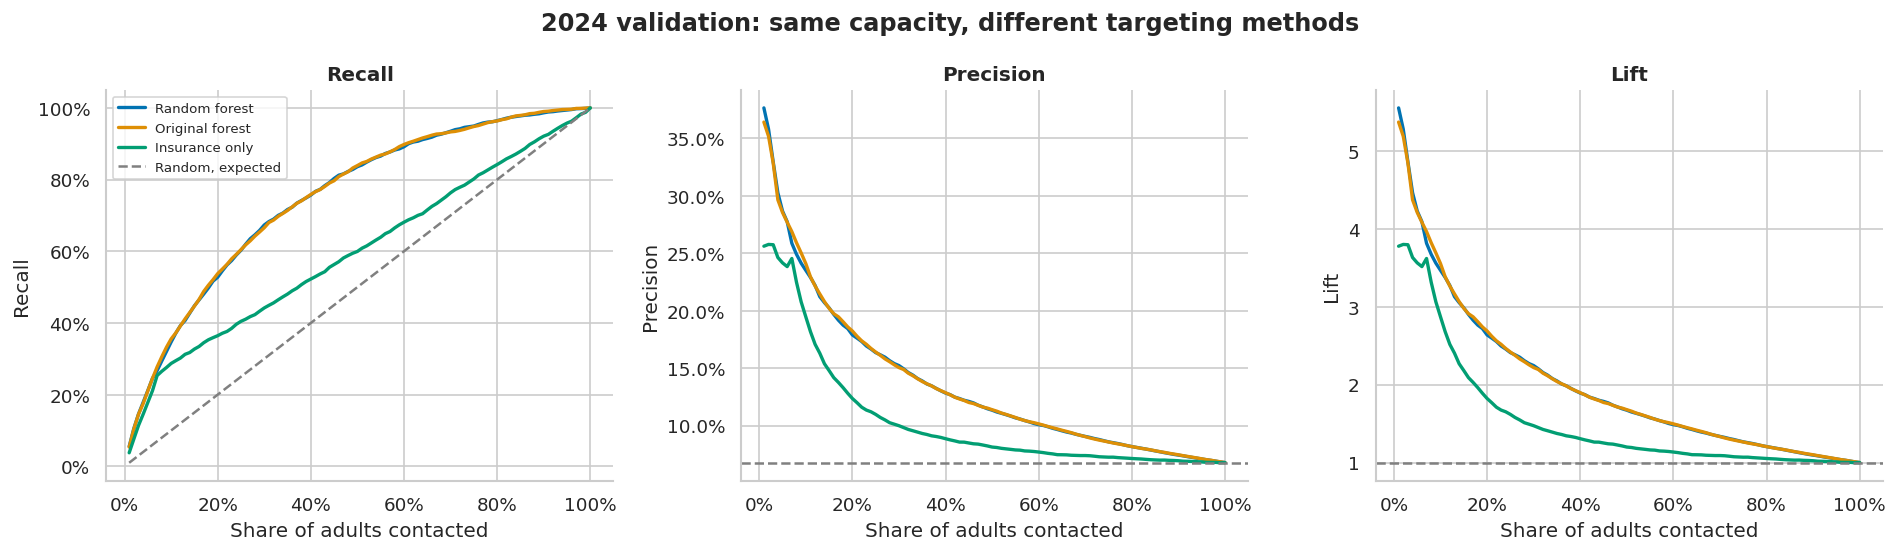

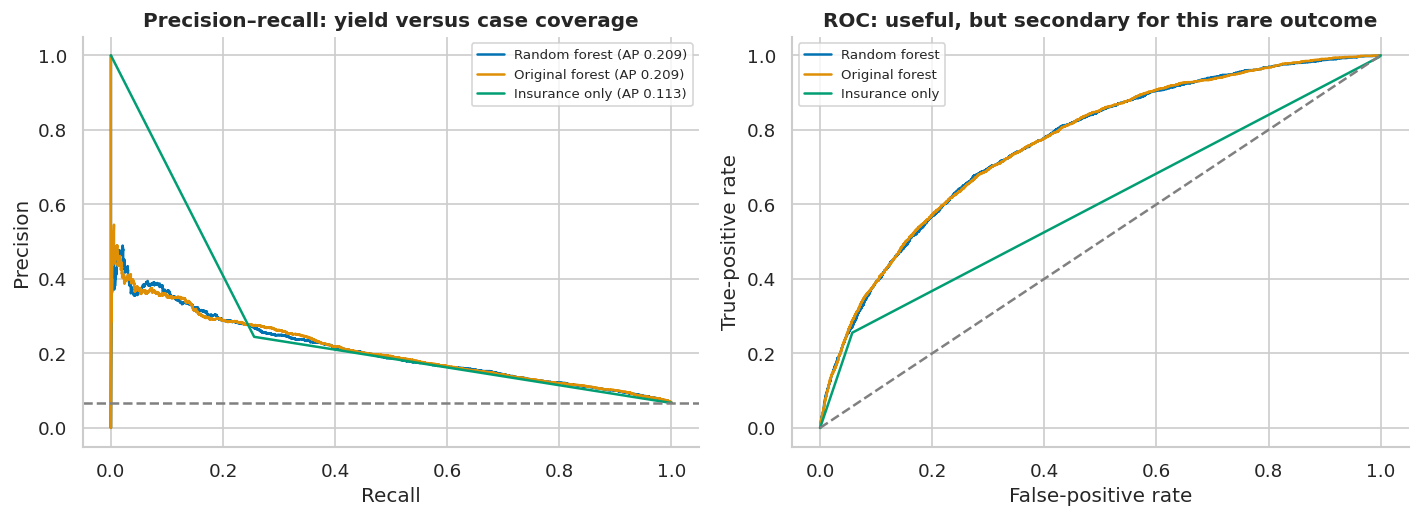

In [ ]:
def plot_capacity_curves(y, score_dictionary, title):
    fractions = np.linspace(0.01, 1.0, 100)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.7))
    for name, scores in score_dictionary.items():
        metrics = pd.DataFrame([capacity_metrics(y, scores, q) for q in fractions])
        for ax, measure in zip(axes, ['recall', 'precision', 'lift']):
            ax.plot(metrics['capacity'], metrics[measure], label=name, linewidth=2)
    axes[0].plot(fractions, fractions, '--', color='grey', label='Random, expected')
    axes[1].axhline(np.mean(y), linestyle='--', color='grey')
    axes[2].axhline(1, linestyle='--', color='grey')
    for ax, measure in zip(axes, ['recall', 'precision', 'lift']):
        ax.set(xlabel='Share of adults contacted', ylabel=measure.capitalize(), title=measure.capitalize())
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        if measure != 'lift': ax.yaxis.set_major_formatter(PercentFormatter(1))
    axes[0].legend(fontsize=8)
    fig.suptitle(title, weight='bold')
    plt.tight_layout(); plt.show()

plot_capacity_curves(y_validation, {name: validation_score_dictionary[name] for name in
    ['Random forest', 'Original forest', 'Insurance only']},
    '2024 validation: same capacity, different targeting methods')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in ['Random forest', 'Original forest', 'Insurance only']:
    scores = validation_score_dictionary[name]
    precision, recall, _ = precision_recall_curve(y_validation, scores)
    axes[0].plot(recall, precision, label=f'{name} (AP {average_precision_score(y_validation, scores):.3f})')
    fpr, tpr, _ = roc_curve(y_validation, scores)
    axes[1].plot(fpr, tpr, label=name)
axes[0].axhline(y_validation.mean(), linestyle='--', color='grey')
axes[0].set(title='Precision–recall: yield versus case coverage', xlabel='Recall', ylabel='Precision')
axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], '--', color='grey')
axes[1].set(title='ROC: useful, but secondary for this rare outcome',
            xlabel='False-positive rate', ylabel='True-positive rate')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

,sample,AP,ROC_AUC,Brier
0,2023 fitted rows (optimistic),0.3330,0.8772,0.1393
1,2024 validation,0.2085,0.7645,0.1498


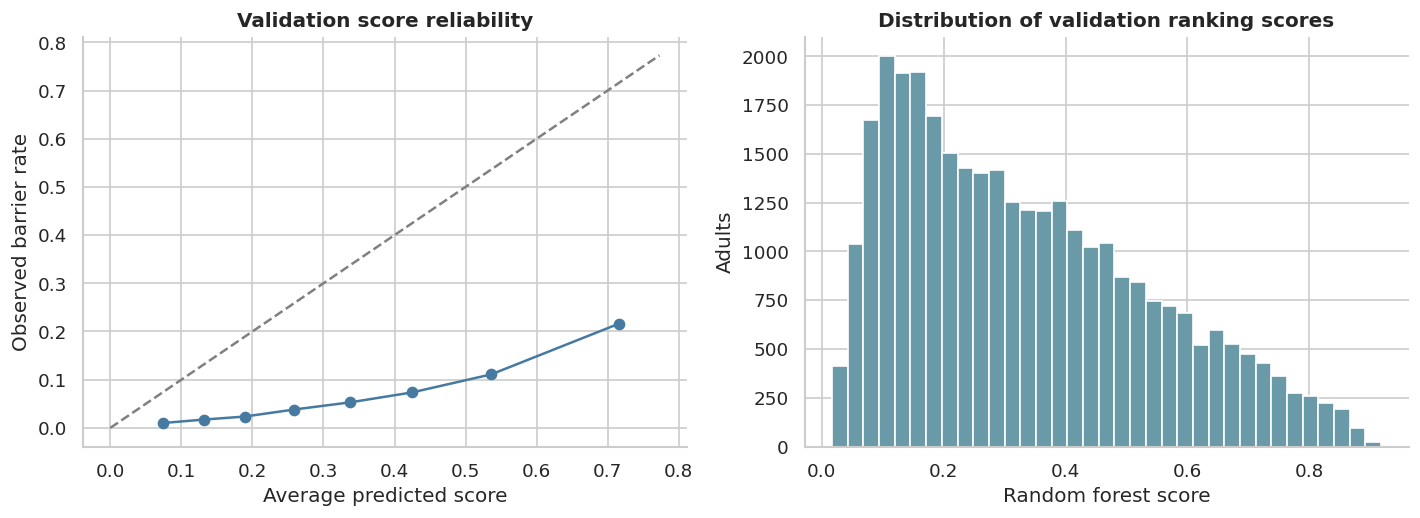

**Interpretation.** Training scores are measured on examples the model already saw, so they can look better than later-year validation. A score of 0.20 should not automatically be interpreted as a reliable 20% individual risk. Calibration checks whether score groups match observed rates; it is distinct from ranking quality. We use scores to order the contact list and do not calibrate or retune after examining 2025.

In [ ]:
train_scores = selected_validation_model.predict_proba(X_train)[:, 1]
display(pd.DataFrame([
    {'sample': '2023 fitted rows (optimistic)', **overall_metrics(y_train, train_scores)},
    {'sample': '2024 validation', **overall_metrics(y_validation, selected_validation_scores)}]))
observed, predicted = calibration_curve(y_validation, selected_validation_scores, n_bins=8, strategy='quantile')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(predicted, observed, marker='o', color='#467AA0')
bound = max(max(predicted), max(observed)) * 1.08
axes[0].plot([0, bound], [0, bound], '--', color='grey')
axes[0].set(title='Validation score reliability', xlabel='Average predicted score',
            ylabel='Observed barrier rate')
axes[1].hist(selected_validation_scores, bins=35, color='#6A99A8')
axes[1].set(title='Distribution of validation ranking scores', xlabel='Random forest score', ylabel='Adults')
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation.** Training scores are measured on examples the model already saw, '
                 'so they can look better than later-year validation. A score of 0.20 should not '
                 'automatically be interpreted as a reliable 20% individual risk. Calibration checks '
                 'whether score groups match observed rates; it is distinct from ranking quality. '
                 'We use scores to order the contact list and do not calibrate or retune after examining 2025.'))

### Interpreting scores and cutoffs
The calibration plot compares score groups with their observed barrier rates. A class-weighted forest may return scores much higher than actual probabilities. The selected cutoff is therefore a decision boundary on this particular score scale, not the share of adults to flag and not an established medical risk level.

Changing a cutoff changes the balance of missed cases and false positives without changing score order. Changing the features or forest can also change the ranking itself. These are different improvements and are evaluated separately. Refitting on both development years can change the score distribution, so the final test evaluates the complete fixed model-and-cutoff procedure.

,predictor,validation_AP_drop,shuffle_SD
9,HINOTCOVE,0.0630,0.0010
7,HEALTH,0.0478,0.0026
1,AGE,0.0338,0.0015
6,POVERTY,0.0186,0.0013
2,SEX,0.0045,0.0017
8,USUALPL,0.0044,0.0015
5,EMPSTAT,0.0030,0.0003
3,HISPRACE,0.0023,0.0003
4,EDUC,0.0015,0.0004
0,REGION,-0.0001,0.0015


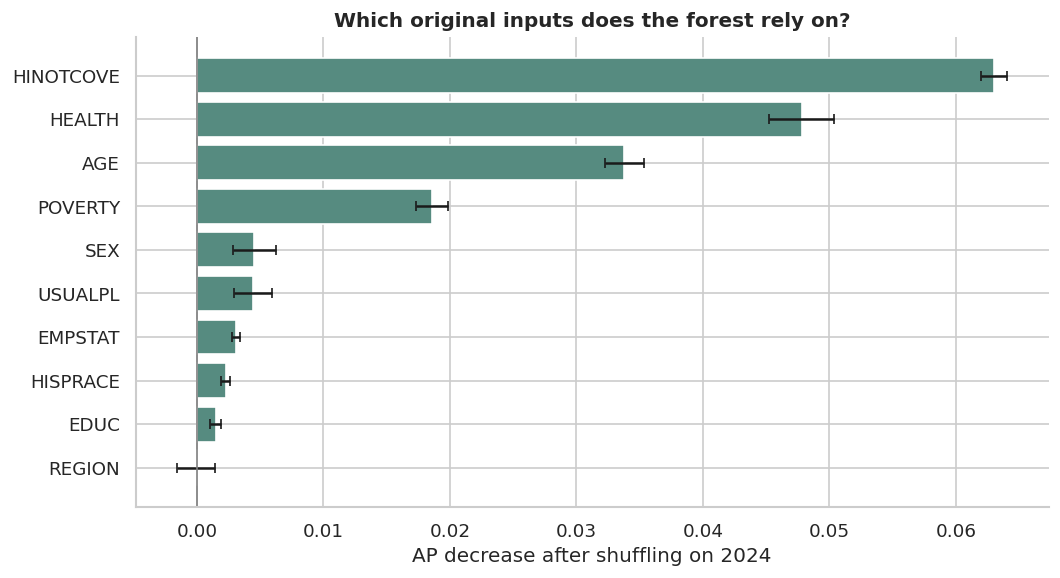

**Business interpretation.** Shuffling one original variable breaks its useful connection with other information while leaving the fitted model fixed. A larger drop means this model relies more on that variable for ranking. Here the largest drops are for **HINOTCOVE, HEALTH, AGE**. This supports checking whether those inputs are available and recorded consistently in a provider setting. Importance does not show the direction of an effect or prove causation. Correlated inputs can share information; a small drop is not proof that a characteristic never matters. Error bars show repeated shuffles, not statistical confidence intervals.

In [ ]:
importance_result = permutation_importance(
    selected_validation_model, X_validation, y_validation, scoring='average_precision',
    n_repeats=4, random_state=RANDOM_STATE, n_jobs=N_JOBS)
importance_table = pd.DataFrame({'predictor': PREDICTORS,
    'validation_AP_drop': importance_result.importances_mean,
    'shuffle_SD': importance_result.importances_std}).sort_values('validation_AP_drop', ascending=False)
display(importance_table)
plot_importance = importance_table.sort_values('validation_AP_drop')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_importance['predictor'], plot_importance['validation_AP_drop'],
        xerr=plot_importance['shuffle_SD'], color='#568B80', capsize=3)
ax.axvline(0, color='grey', linewidth=1)
ax.set(title='Which original inputs does the forest rely on?', xlabel='AP decrease after shuffling on 2024')
plt.tight_layout(); plt.show()
display(Markdown('**Business interpretation.** Shuffling one original variable breaks its useful '
                 'connection with other information while leaving the fitted model fixed. A larger '
                 'drop means this model relies more on that variable for ranking. Here the largest '
                 'drops are for **' + ', '.join(importance_table.head(3)['predictor']) + '**. '
                 'This supports checking whether those inputs are available and recorded consistently '
                 'in a provider setting. Importance does not show the direction of an effect or prove '
                 'causation. Correlated inputs can share information; a small drop is not proof that '
                 'a characteristic never matters. Error bars show repeated shuffles, not statistical confidence intervals.'))

In [ ]:
def subgroup_report(records, scores, fraction):
    selected = select_top_k(scores, int(np.ceil(len(records) * fraction)))
    d = records.copy().assign(selected=selected)
    rows = []
    for column in ['HINOTCOVE', 'SEX', 'HISPRACE']:
        for value, group in d.groupby(column, dropna=False):
            tp = int(group.loc[group['selected'], 'target'].sum())
            cases = int(group['target'].sum())
            contacts = int(group['selected'].sum())
            rows.append({'variable': column, 'group': category_label(value, column), 'adults': len(group),
                          'actual_cases': cases, 'contacts': contacts, 'cases_found': tp,
                          'selection_rate': contacts / len(group),
                          'recall': tp / cases if cases else np.nan,
                          'precision': tp / contacts if contacts else np.nan})
    return pd.DataFrame(rows)

validation_subgroups = subgroup_report(validation, selected_validation_scores, 0.10)
display(validation_subgroups)
display(Markdown('**Subgroup check, illustrative 10% scenario.** The same overall contact list is '
                 'used for every group; each group is not assigned a separate quota. Group recall '
                 'shows which reported cases the procedure misses. Differences should be reviewed '
                 'alongside group sample sizes and prevalence. They are descriptive checks, not a '
                 'complete fairness assessment or a reason to infer individual need from group membership.'))

,variable,group,adults,actual_cases,contacts,cases_found,selection_rate,recall,precision
0,HINOTCOVE,Covered,29980,1625,1408,271,0.0470,0.1668,0.1925
1,HINOTCOVE,Not covered,2295,561,1825,489,0.7952,0.8717,0.2679
2,HINOTCOVE,Missing,79,9,3,1,0.0380,0.1111,0.3333
3,SEX,Male,14850,903,1308,301,0.0881,0.3333,0.2301
4,SEX,Female,17499,1292,1928,460,0.1102,0.3560,0.2386
5,SEX,Missing,5,0,0,0,0.0000,NaN,NaN
6,HISPRACE,Hispanic,4712,439,1056,239,0.2241,0.5444,0.2263
7,HISPRACE,Non-Hispanic White,21631,1350,1563,394,0.0723,0.2919,0.2521
8,HISPRACE,Non-Hispanic Black,3234,241,391,80,0.1209,0.3320,0.2046
9,HISPRACE,Non-Hispanic Asian,1851,62,67,11,0.0362,0.1774,0.1642


**Subgroup check, illustrative 10% scenario.** The same overall contact list is used for every group; each group is not assigned a separate quota. Group recall shows which reported cases the procedure misses. Differences should be reviewed alongside group sample sizes and prevalence. They are descriptive checks, not a complete fairness assessment or a reason to infer individual need from group membership.

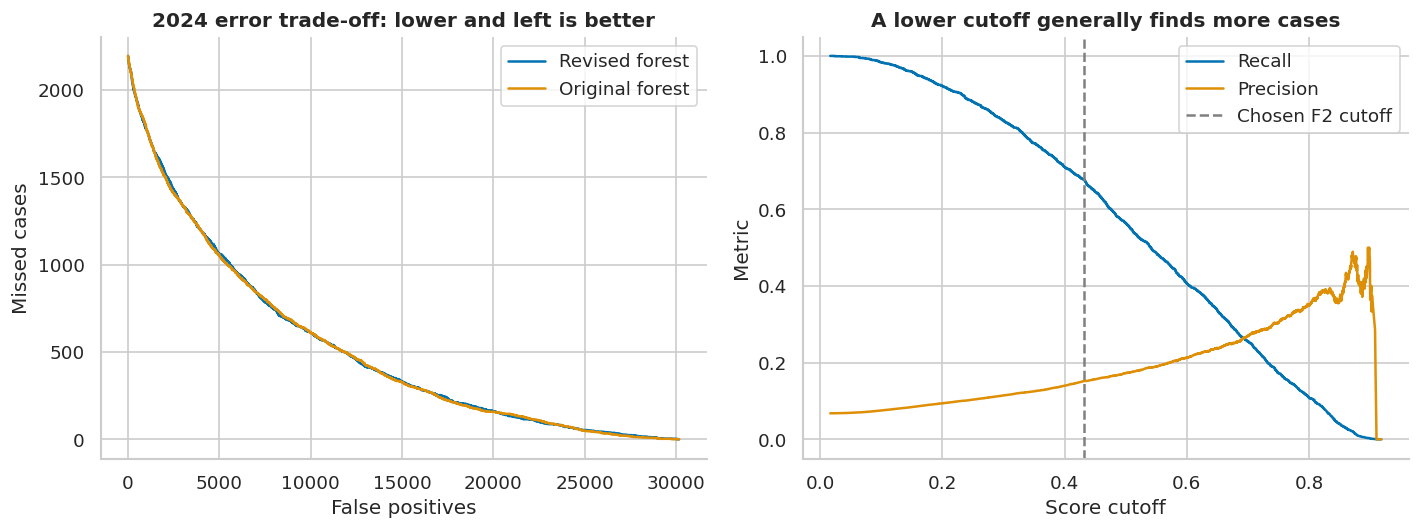

In [ ]:
validation_thresholds = threshold_table(y_validation, selected_validation_scores)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(validation_thresholds['false_positives'], validation_thresholds['missed_cases'], label='Revised forest')
old_thresholds = threshold_table(y_validation, original_validation_scores)
axes[0].plot(old_thresholds['false_positives'], old_thresholds['missed_cases'], label='Original forest')
axes[0].set(xlabel='False positives', ylabel='Missed cases', title='2024 error trade-off: lower and left is better')
axes[0].legend()
axes[1].plot(validation_thresholds['cutoff'], validation_thresholds['recall'], label='Recall')
axes[1].plot(validation_thresholds['cutoff'], validation_thresholds['precision'], label='Precision')
axes[1].axvline(fixed_recall_cutoff, linestyle='--', color='grey', label='Chosen F2 cutoff')
axes[1].set(xlabel='Score cutoff', ylabel='Metric', title='A lower cutoff generally finds more cases')
axes[1].legend(); plt.tight_layout(); plt.show()

### Priority-population profiles: a separate descriptive task
Classification answers **who to rank first**; segmentation asks **what kinds of people appear in a priority population**. Clustering does not replace the classifier, and it does not establish which intervention will work.

To make this second task concrete, we use the highest-scoring **20% of the 2024 validation sample as an illustrative planning population**. This is a scope for describing profiles, not a mandatory contact budget. The adults were scored by a forest fitted only on 2023, so their own outcomes did not teach the model that generated these scores. We later show how profile shares change at other capacities.

We use **k-prototypes**, which groups people using both numeric age and categorical answers. Age is standardised within this development planning population. Category mismatches receive a fixed weight of 0.5; this balances age differences with categorical differences and is a modelling convention, not a learned measure of support need.

The clustering inputs are **age, poverty, health, insurance, usual place of care, employment and education**. These cover life stage, financial circumstances, health and access. Race, sex and region are left out of the clustering distance so they do not directly define outreach-support profiles. Targets, scores, weights, year and identifiers are also excluded. An insured or relatively higher-income profile can still appear because the original priority list uses combined information.

We compare 2–5 clusters using separation (silhouette), minimum group size and stability across repeated starts (adjusted Rand index, ARI). These assess descriptive usefulness, not predictive accuracy. We prefer the smallest stable solution within 0.02 of the best silhouette, with each group at least 5% of the planning pool. Stability of 0.60 is an exploratory screen, not a universal standard. Target rates are inspected **only after** this choice and never used to select the clusters.

In [ ]:
assert not TEST_OPENED
PROFILE_COLUMNS = ['AGE', 'POVERTY', 'HEALTH', 'HINOTCOVE', 'USUALPL', 'EMPSTAT', 'EDUC']
PROFILE_CATS = PROFILE_COLUMNS[1:]
PROFILE_CAT_INDEX = list(range(1, len(PROFILE_COLUMNS)))
assert set(PROFILE_COLUMNS).isdisjoint(EXCLUDED + ['score'])
planning_mask = select_top_k(selected_validation_scores, int(np.ceil(PROFILE_FRACTION * len(validation))))
planning_pool = validation.loc[planning_mask].copy().reset_index(drop=True)
profile_age_imputer = SimpleImputer(strategy='median')
profile_age_scaler = StandardScaler()
profile_age = profile_age_scaler.fit_transform(profile_age_imputer.fit_transform(planning_pool[['AGE']]))
FIT_LOG.append({'step': 'Profile age imputer and scaler', 'years': [2024], 'rows': len(planning_pool)})

def profile_matrix(records):
    age = profile_age_scaler.transform(profile_age_imputer.transform(records[['AGE']])).ravel()
    cats = records[PROFILE_CATS].fillna(-1).astype(int).astype(str).to_numpy()
    matrix = np.empty((len(records), len(PROFILE_COLUMNS)), dtype=object)
    matrix[:, 0] = age
    matrix[:, 1:] = cats
    return matrix

planning_matrix = profile_matrix(planning_pool)
rng = np.random.default_rng(RANDOM_STATE)
silhouette_idx = rng.choice(len(planning_pool), min(800, len(planning_pool)), replace=False)
small_matrix = planning_matrix[silhouette_idx]
small_age = small_matrix[:, 0].astype(float)
profile_distance = (small_age[:, None] - small_age[None, :]) ** 2
for j in PROFILE_CAT_INDEX:
    profile_distance += 0.5 * (small_matrix[:, j, None] != small_matrix[None, :, j])
np.fill_diagonal(profile_distance, 0.0)

cluster_candidates, cluster_rows = {}, []
for k in range(2, 6):
    model = KPrototypes(n_clusters=k, init='Huang', n_init=3, max_iter=40,
                        gamma=0.5, random_state=RANDOM_STATE, n_jobs=1, verbose=0)
    labels = model.fit_predict(planning_matrix, categorical=PROFILE_CAT_INDEX)
    FIT_LOG.append({'step': f'Profile k={k}', 'years': [2024], 'rows': len(planning_pool)})
    repeat_labels = []
    for seed in [17, 41]:
        repeat = KPrototypes(n_clusters=k, init='Huang', n_init=2, max_iter=40,
                             gamma=0.5, random_state=seed, n_jobs=1, verbose=0)
        repeat_labels.append(repeat.fit_predict(planning_matrix, categorical=PROFILE_CAT_INDEX))
        FIT_LOG.append({'step': f'Profile stability k={k}, seed={seed}', 'years': [2024], 'rows': len(planning_pool)})
    stability = np.mean([adjusted_rand_score(labels, repeat) for repeat in repeat_labels])
    sizes = np.bincount(labels, minlength=k) / len(labels)
    silhouette = silhouette_score(profile_distance, labels[silhouette_idx], metric='precomputed')
    cluster_candidates[k] = model
    cluster_rows.append({'k': k, 'silhouette': silhouette, 'start_stability_ARI': stability,
                         'smallest_share': sizes.min(), 'within_cluster_cost': model.cost_})
cluster_diagnostics = pd.DataFrame(cluster_rows)
eligible = cluster_diagnostics.loc[(cluster_diagnostics['smallest_share'] >= 0.05) &
                                    (cluster_diagnostics['start_stability_ARI'] >= 0.60)]
profiles_stable = not eligible.empty
if eligible.empty:
    eligible = cluster_diagnostics.copy()
best_silhouette = eligible['silhouette'].max()
chosen_k = int(eligible.loc[eligible['silhouette'] >= best_silhouette - 0.02, 'k'].min())
profile_model = cluster_candidates[chosen_k]
planning_clusters = profile_model.predict(planning_matrix, categorical=PROFILE_CAT_INDEX)
cluster_age_order = planning_pool.assign(cluster=planning_clusters).groupby('cluster')['AGE'].mean().sort_values().index
PROFILE_NAMES = {int(cluster): f'Profile {chr(65+i)}' for i, cluster in enumerate(cluster_age_order)}
display(cluster_diagnostics)
print(f'Planning adults: {len(planning_pool):,}; chosen clusters: {chosen_k}; stability screen passed: {profiles_stable}')

Planning adults: 6,471; chosen clusters: 2; stability screen passed: True


,k,silhouette,start_stability_ARI,smallest_share,within_cluster_cost
0,2,0.5030,1.0000,0.4217,"11,684.8457"
1,3,0.3120,0.7141,0.2748,"10,516.9371"
2,4,0.1965,0.6618,0.2142,"9,868.1890"
3,5,0.1647,0.4792,0.1179,"9,527.5170"


,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,3742,0.5783,34.0000,0.4107,0.5390,0.2231,0.2688,0.2050,0.1873
1,Profile B,2729,0.4217,58.0000,0.2448,0.6563,0.6233,0.1411,0.5412,0.1675


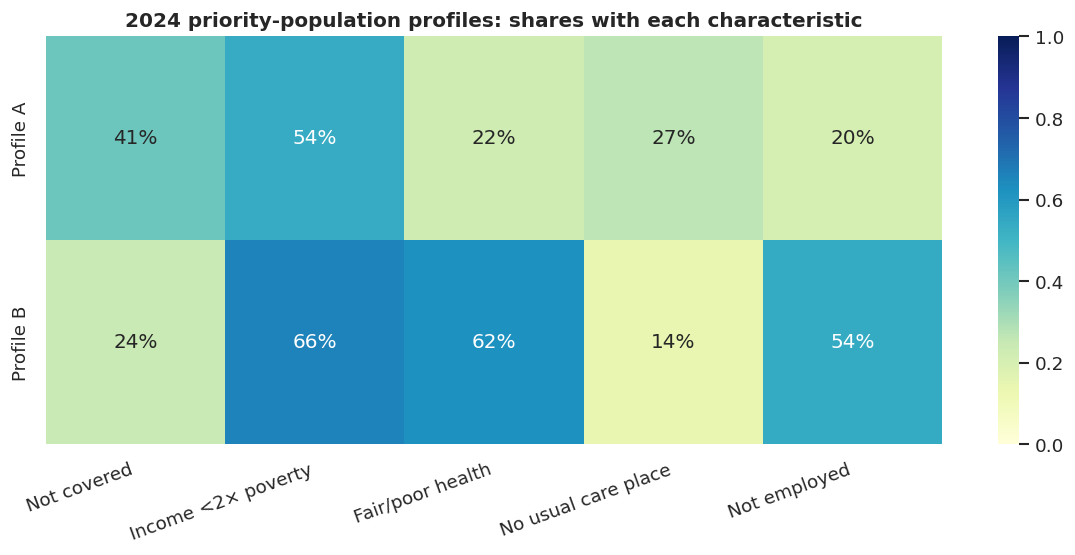

,profile,possible_outreach_focus
0,Profile A,Ask about current cost barriers and explain available assistance pathways. Explore help connecting to a regular source of care.
1,Profile B,Review cost concerns alongside care navigation and existing coverage. Coordinate follow-up with the existing care team where appropriate.


**How to use the profiles.** The table describes group averages; individuals within a profile can have different needs. Suggested outreach focuses are hypotheses for a provider to assess, not interventions shown to work by these data. Clustering does not verify a positive prediction. The reported-barrier rate was added only after the groups were fixed, so it did not determine their number or membership. Restart stability is not evidence that these groups will remain stable in another provider.

In [ ]:
LOWER_INCOME_CODES = [11, 12, 13, 21, 22, 23, 24]

def profile_summary(records, cluster_labels):
    data = records.assign(profile=[PROFILE_NAMES[int(c)] for c in cluster_labels])
    rows = []
    for name, g in data.groupby('profile'):
        rows.append({'profile': name, 'adults': len(g), 'share': len(g) / len(data),
                      'median_age': g['AGE'].median(),
                      'uninsured': g['HINOTCOVE'].eq(2).mean(),
                      'income_below_2x_poverty': g['POVERTY'].isin(LOWER_INCOME_CODES).mean(),
                      'fair_or_poor_health': g['HEALTH'].isin([4, 5]).mean(),
                      'no_usual_place': g['USUALPL'].eq(1).mean(),
                      'not_employed': g['EMPSTAT'].eq(200).mean(),
                      'reported_barrier_rate': g['target'].mean()})
    return pd.DataFrame(rows)

planning_profile_summary = profile_summary(planning_pool, planning_clusters)
display(planning_profile_summary)
profile_plot_columns = ['uninsured', 'income_below_2x_poverty', 'fair_or_poor_health',
                         'no_usual_place', 'not_employed']
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(planning_profile_summary.set_index('profile')[profile_plot_columns],
            annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=1, ax=ax)
ax.set(title='2024 priority-population profiles: shares with each characteristic', xlabel='', ylabel='')
ax.set_xticklabels(['Not covered', 'Income <2× poverty', 'Fair/poor health',
                    'No usual care place', 'Not employed'], rotation=20, ha='right')
plt.tight_layout(); plt.show()

def support_hypotheses(summary):
    rows = []
    for _, r in summary.iterrows():
        if r['uninsured'] >= 0.5:
            suggestion = 'Check coverage/enrolment options and financial-assistance needs.'
        elif r['fair_or_poor_health'] >= 0.4:
            suggestion = 'Review cost concerns alongside care navigation and existing coverage.'
        else:
            suggestion = 'Ask about current cost barriers and explain available assistance pathways.'
        if r['no_usual_place'] >= 0.20:
            suggestion += ' Explore help connecting to a regular source of care.'
        else:
            suggestion += ' Coordinate follow-up with the existing care team where appropriate.'
        rows.append({'profile': r['profile'], 'possible_outreach_focus': suggestion})
    return pd.DataFrame(rows)

support_table = support_hypotheses(planning_profile_summary)
display(support_table)
display(Markdown('**How to use the profiles.** The table describes group averages; individuals within '
                 'a profile can have different needs. Suggested outreach focuses are hypotheses for '
                 'a provider to assess, not interventions shown to work by these data. Clustering '
                 'does not verify a positive prediction. The reported-barrier rate was added only '
                 'after the groups were fixed, so it did not determine their number or membership. '
                 'Restart stability is not evidence that these groups will remain stable in another provider.'))

### Interpreting profiles after changing the classifier
The profiles are refitted using the revised forest's **2024 top-20% planning population**, before the test is opened. This remains a descriptive planning scenario, not a required contact budget. It keeps the original segmentation scope comparable. Later, we also assign adults flagged by the recall-first rule to these fixed profiles. Because that rule can produce a broader population, its profile mix may differ and its descriptive fit should be reviewed.

Higher false positives do not become confirmed cases simply because they fit a profile. Clusters describe characteristics; follow-up must still establish current support needs.

### Freeze the complete procedure before 2025
The forest configuration, baseline procedures, capacity scenarios, tie-breaking rule and cluster definitions are now fixed. **Refitting** means training the chosen prediction procedure again on all 2023–2024 data. It gives the final model more development examples without using 2025.

The profile model remains the one developed on the 2024 planning population; later adults are assigned to its existing groups. We do not fit new clusters after opening the test file. Because the final forest uses an additional training year, its score distribution and prioritised population can differ from the validation model's. Profile membership and composition therefore need to be checked on later data.

In [ ]:
assert not TEST_OPENED
X_development, y_development = development[PREDICTORS], development['target']
final_model = clone(selected_validation_model)
final_original = clone(original_validation_model)
final_insurance = clone(insurance_validation_model)
final_constant = clone(constant_validation_model)
fit_development(final_model, X_development, y_development, development, 'FINAL revised forest: 2023–2024')
fit_development(final_original, X_development, y_development, development, 'FINAL original forest: 2023–2024')
fit_development(final_insurance, X_development, y_development, development, 'FINAL insurance baseline: 2023–2024')
fit_development(final_constant, X_development, y_development, development, 'FINAL constant baseline: 2023–2024')
frozen_choices = {'predictors': PREDICTORS, 'candidate': selected_forest_name,
    'forest_parameters': final_model.named_steps['model'].get_params(),
    'selection': '2023 five-fold AP screen, 2024 F2 selection',
    'recall_first_cutoff': fixed_recall_cutoff, 'conservative_cutoff': fixed_conservative_cutoff,
    'original_f2_cutoff': original_fixed_cutoff, 'ordered_code_maps': ORDER_MAPS,
    'capacities': list(CAPACITIES), 'profile_k': chosen_k, 'profile_columns': PROFILE_COLUMNS,
    'profile_planning_fraction': PROFILE_FRACTION, 'profile_names': PROFILE_NAMES, 'tie_seed': RANDOM_STATE}
def freeze_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()
CHOICE_DIGEST = freeze_digest(frozen_choices)
import pickle
fitted_state_digest = hashlib.sha256(pickle.dumps((final_model, final_original, final_insurance,
    final_constant, profile_age_imputer, profile_age_scaler, profile_model))).hexdigest()
FITS_BEFORE_TEST = len(FIT_LOG)
display(pd.DataFrame(FIT_LOG))
print('All models, cutoffs and profile definitions are fixed before opening 2025.')

All models, cutoffs and profile definitions are fixed before opening 2025.


,step,years,rows
0,Original forest reference: 2023,[2023],29276
1,One-hot: 2023 five-fold search,[2023],29276
2,One-hot finalist 1: 2023 fit,[2023],29276
3,One-hot finalist 2: 2023 fit,[2023],29276
4,Ordered: 2023 five-fold search,[2023],29276
5,Ordered finalist 1: 2023 fit,[2023],29276
6,Ordered finalist 2: 2023 fit,[2023],29276
7,Hybrid: 2023 five-fold search,[2023],29276
8,Hybrid finalist 1: 2023 fit,[2023],29276
9,Hybrid finalist 2: 2023 fit,[2023],29276


## Part 8: Final Out-of-Time Evaluation — Supplied 2025 Sample
### Apply the fixed procedure to a later group
Only now do we open the evaluation file. We apply the same fixed cleaning rules and learned preprocessing, then produce scores. We do not choose a new feature, forest setting, capacity, cutoff or cluster definition from these outcomes.

The test asks whether the complete procedure transfers to **later respondents**, rather than predicting changes in the same people. The year was examined in earlier project work. That history does not mean this run fits on 2025, but it limits how independently the final results confirm the approach. No further model adjustments are made from this evaluation.

In [ ]:
assert not TEST_OPENED
if not TEST_PATH.exists():
    raise FileNotFoundError('Place nhis_2025.csv beside the notebook.')
TEST_OPENED = True
evaluation_raw = pd.read_csv(TEST_PATH, dtype={'NHISPID': str})
verify_structure(evaluation_raw, {2025}, 'Evaluation file')
evaluation = prepare_nhis(evaluation_raw)
assert evaluation['NHISPID'].is_unique and evaluation['NHISPID'].notna().all()
assert set(development['NHISPID']).isdisjoint(evaluation['NHISPID'])
assert evaluation['AGE'].dropna().between(18, 85).all()
X_evaluation, y_evaluation = evaluation[PREDICTORS], evaluation['target']
evaluation_scores = final_model.predict_proba(X_evaluation)[:, 1]
insurance_scores = final_insurance.predict_proba(X_evaluation)[:, 1]
constant_scores = final_constant.predict_proba(X_evaluation)[:, 1]
evaluation_score_dictionary = {'Random forest': evaluation_scores,
    'Insurance only': insurance_scores, 'Constant score / random tie order': constant_scores}
display(cleaning_summary(evaluation_raw, evaluation))
display(pd.DataFrame({'adults': [len(evaluation)], 'reported_cases': [int(y_evaluation.sum())],
                      'sample_prevalence': [y_evaluation.mean()],
                      'weighted_prevalence': [weighted_binary_rate(evaluation)]}))

evaluation_metrics = pd.DataFrame([{'method': name, **overall_metrics(y_evaluation, scores)}
                                  for name, scores in evaluation_score_dictionary.items()])
evaluation_capacity_table = table_at_capacities(y_evaluation, evaluation_score_dictionary)
random_expected = []
for q in CAPACITIES:
    k = int(np.ceil(q * len(y_evaluation)))
    random_expected.append({'method': 'Random selection: expected', 'capacity': q, 'contacts': k,
        'cases_found': k * y_evaluation.mean(), 'precision': y_evaluation.mean(),
        'recall': k / len(y_evaluation), 'lift': 1.0})
random_expected = pd.DataFrame(random_expected)
display(evaluation_metrics)
display(evaluation_capacity_table[['method', 'capacity', 'contacts', 'cases_found',
    'precision', 'recall', 'lift', 'missed_cases', 'false_positives']])
display(random_expected)

original_evaluation_scores = final_original.predict_proba(X_evaluation)[:, 1]
evaluation_score_dictionary['Original forest'] = original_evaluation_scores
evaluation_capacity_table = table_at_capacities(y_evaluation, evaluation_score_dictionary)
recall_first_predictions = evaluation_scores >= fixed_recall_cutoff
conservative_predictions = evaluation_scores >= fixed_conservative_cutoff
original_f2_predictions = original_evaluation_scores >= original_fixed_cutoff
original_10_predictions = select_top_k(original_evaluation_scores, int(np.ceil(0.10 * len(evaluation))))
operating_results = pd.DataFrame([
    {'procedure': 'Original forest: illustrative 10% list', **binary_metrics(y_evaluation, original_10_predictions)},
    {'procedure': 'Original forest: F2 cutoff', **binary_metrics(y_evaluation, original_f2_predictions)},
    {'procedure': 'Revised forest: F2 cutoff', **binary_metrics(y_evaluation, recall_first_predictions)},
    {'procedure': 'Revised forest: conservative cutoff', **binary_metrics(y_evaluation, conservative_predictions)}])
print('Primary error-count comparison — all decision rules were frozen on 2024:')
display(operating_results)


Primary error-count comparison — all decision rules were frozen on 2024:


,stage,rows
0,Raw records,30264
1,Sample adults,24215
2,Valid adult target,24018
3,Retained after positive-weight check,24018


,adults,reported_cases,sample_prevalence,weighted_prevalence
0,24018,1351,0.0562,0.0608


,method,AP,ROC_AUC,Brier
0,Random forest,0.2304,0.7940,0.1490
1,Insurance only,0.1113,0.6190,0.0506
2,Constant score / random tie order,0.0562,0.5000,0.0531


,method,capacity,contacts,cases_found,precision,recall,lift,missed_cases,false_positives
0,Random forest,0.0500,1201,355,0.2956,0.2628,5.2549,996,846
1,Random forest,0.1000,2402,556,0.2315,0.4115,4.1151,795,1846
2,Random forest,0.2000,4804,797,0.1659,0.5899,2.9494,554,4007
3,Random forest,0.3000,7206,970,0.1346,0.7180,2.3931,381,6236
4,Random forest,0.4000,9608,1074,0.1118,0.7950,1.9873,277,8534
5,Random forest,0.5000,12009,1171,0.0975,0.8668,1.7335,180,10838
6,Insurance only,0.0500,1201,282,0.2348,0.2087,4.1743,1069,919
7,Insurance only,0.1000,2402,434,0.1807,0.3212,3.2122,917,1968
8,Insurance only,0.2000,4804,550,0.1145,0.4071,2.0354,801,4254
9,Insurance only,0.3000,7206,649,0.0901,0.4804,1.6011,702,6557


,method,capacity,contacts,cases_found,precision,recall,lift
0,Random selection: expected,0.0500,1201,67.5556,0.0562,0.0500,1.0000
1,Random selection: expected,0.1000,2402,135.1112,0.0562,0.1000,1.0000
2,Random selection: expected,0.2000,4804,270.2225,0.0562,0.2000,1.0000
3,Random selection: expected,0.3000,7206,405.3337,0.0562,0.3000,1.0000
4,Random selection: expected,0.4000,9608,540.4450,0.0562,0.4000,1.0000
5,Random selection: expected,0.5000,12009,675.5000,0.0562,0.5000,1.0000


,procedure,cases_found,missed_cases,false_positives,true_negatives,flagged,precision,recall,F2
0,Original forest: illustrative 10% list,553,798,1849,20818,2402,0.2302,0.4093,0.3542
1,Original forest: F2 cutoff,964,387,6483,16184,7447,0.1294,0.7135,0.3751
2,Revised forest: F2 cutoff,975,376,6369,16298,7344,0.1328,0.7217,0.3824
3,Revised forest: conservative cutoff,545,806,1763,20904,2308,0.2361,0.4034,0.3533


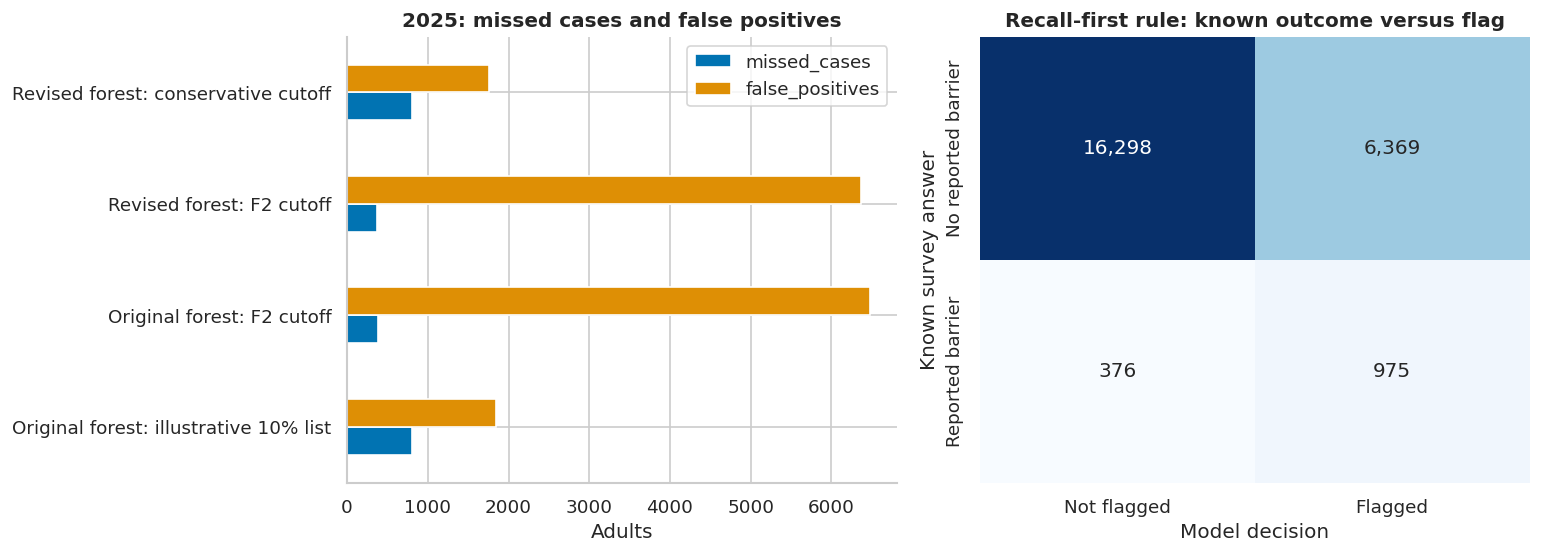

**Recall-first result.** The revised forest flags **7,344 adults**, finds **975 of 1,351 cases** (72.2% recall), misses **376**, and produces **6,369 false positives**. Precision is **13.3%**. These are the two sides of the changed operating decision; the miss reduction should not be reported alone.

**Separate the effects.** The original forest under its own F2 cutoff misses **387** cases and produces **6,483** false positives. This is the more relevant control for whether changing the forest adds value. The earlier 10% list is a shorter-list reference, not an equal-workload comparison with the F2 rule.

**Conservative alternative.** Its frozen cutoff misses **806** cases with **1,763** false positives. The 2024 constraint does not automatically transfer to 2025; compare these counts with the original 10% row before describing it as a no-extra-false-positive improvement.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
operating_results.set_index('procedure')[['missed_cases', 'false_positives']].plot.barh(ax=axes[0])
axes[0].set(title='2025: missed cases and false positives', xlabel='Adults', ylabel='')
matrix = confusion_matrix(y_evaluation, recall_first_predictions.astype(int), labels=[0, 1])
sns.heatmap(matrix, annot=True, fmt=',d', cbar=False, cmap='Blues', ax=axes[1],
    xticklabels=['Not flagged', 'Flagged'], yticklabels=['No reported barrier', 'Reported barrier'])
axes[1].set(title='Recall-first rule: known outcome versus flag', xlabel='Model decision', ylabel='Known survey answer')
plt.tight_layout(); plt.show()
new_point = operating_results.iloc[2]
old_point = operating_results.iloc[0]
old_f2_point = operating_results.iloc[1]
conservative_point = operating_results.iloc[3]
display(Markdown(f"**Recall-first result.** The revised forest flags **{int(new_point['flagged']):,} adults**, "
    f"finds **{int(new_point['cases_found']):,} of {int(y_evaluation.sum()):,} cases** "
    f"({new_point['recall']:.1%} recall), misses **{int(new_point['missed_cases']):,}**, and produces "
    f"**{int(new_point['false_positives']):,} false positives**. Precision is **{new_point['precision']:.1%}**. "
    'These are the two sides of the changed operating decision; the miss reduction should not be reported alone.'))
display(Markdown(f"**Separate the effects.** The original forest under its own F2 cutoff misses "
    f"**{int(old_f2_point['missed_cases']):,}** cases and produces **{int(old_f2_point['false_positives']):,}** "
    'false positives. This is the more relevant control for whether changing the forest adds value. '
    'The earlier 10% list is a shorter-list reference, not an equal-workload comparison with the F2 rule.'))
display(Markdown(f"**Conservative alternative.** Its frozen cutoff misses "
    f"**{int(conservative_point['missed_cases']):,}** cases with "
    f"**{int(conservative_point['false_positives']):,}** false positives. "
    'The 2024 constraint does not automatically transfer to 2025; compare these counts with the original '
    '10% row before describing it as a no-extra-false-positive improvement.'))

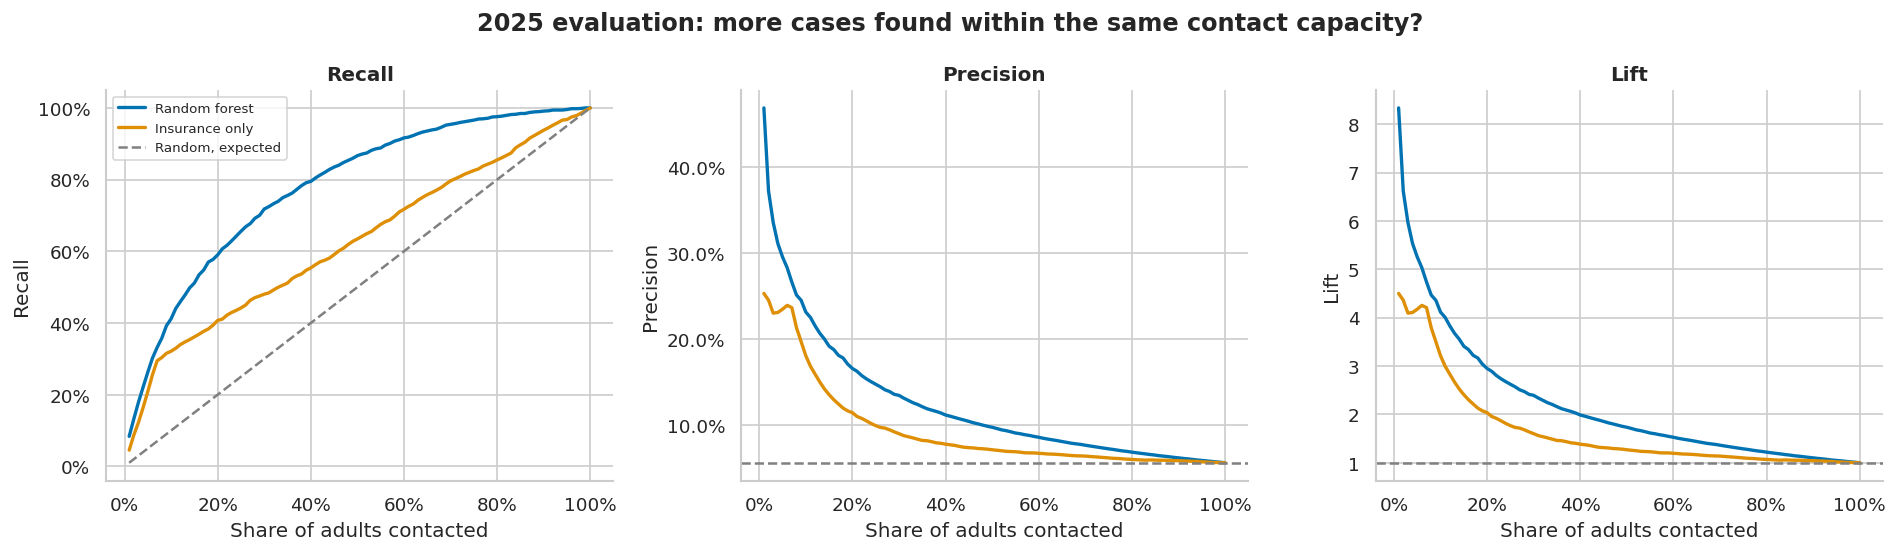

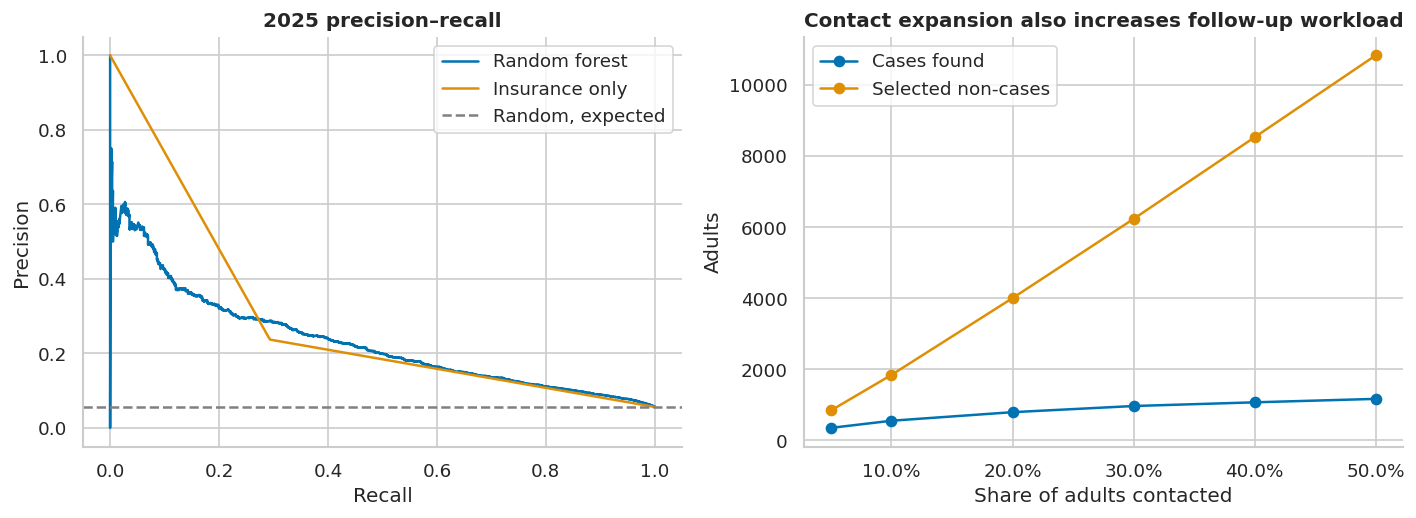

In [ ]:
plot_capacity_curves(y_evaluation, {'Random forest': evaluation_scores, 'Insurance only': insurance_scores},
                     '2025 evaluation: more cases found within the same contact capacity?')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, scores in [('Random forest', evaluation_scores), ('Insurance only', insurance_scores)]:
    precision, recall, _ = precision_recall_curve(y_evaluation, scores)
    axes[0].plot(recall, precision, label=name)
axes[0].axhline(y_evaluation.mean(), color='grey', linestyle='--', label='Random, expected')
axes[0].set(title='2025 precision–recall', xlabel='Recall', ylabel='Precision')
axes[0].legend()
rf_capacity = evaluation_capacity_table.loc[evaluation_capacity_table['method'].eq('Random forest')]
axes[1].plot(rf_capacity['capacity'], rf_capacity['cases_found'], marker='o', label='Cases found')
axes[1].plot(rf_capacity['capacity'], rf_capacity['false_positives'], marker='o', label='Selected non-cases')
axes[1].set(title='Contact expansion also increases follow-up workload',
            xlabel='Share of adults contacted', ylabel='Adults')
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
plt.tight_layout(); plt.show()

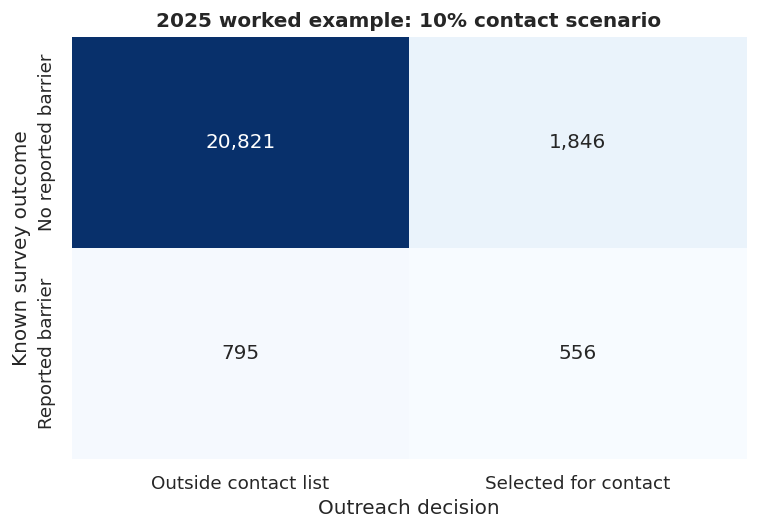

**Secondary same-capacity worked example.** If capacity were **2,402 contacts** out of **24,018 eligible adults**, the random forest identifies **556 of 1,351 reported cases (41.2% recall)**. Insurance-only targeting identifies **434** at the same contact count; the forest therefore finds **122 additional cases**. Random selection would find about **135**, on average. Precision is **23.1%**, or about 23 actual cases per 100 contacts. Lift is **4.12**, meaning that concentration is 4.12 times the random-selection expectation, not 4.12 times the accuracy.

**What it misses.** At this capacity the procedure leaves **795 actual cases outside the list** and selects **1,846 people who did not report this outcome**. These selected non-cases may still have other support needs, but this dataset does not establish them. A lower capacity can improve yield per contact while missing more total cases; a higher capacity finds more cases but adds follow-up workload. A provider must make that resource decision.

In [ ]:
example_q = 0.10  # Worked example only, not the provider's established budget.
example_rf = capacity_metrics(y_evaluation, evaluation_scores, example_q)
example_insurance = capacity_metrics(y_evaluation, insurance_scores, example_q)
example_selected = select_top_k(evaluation_scores, example_rf['contacts'])
example_matrix = confusion_matrix(y_evaluation, example_selected.astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 4.6))
sns.heatmap(example_matrix, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Outside contact list', 'Selected for contact'],
            yticklabels=['No reported barrier', 'Reported barrier'])
ax.set(title='2025 worked example: 10% contact scenario', xlabel='Outreach decision', ylabel='Known survey outcome')
plt.tight_layout(); plt.show()

display(Markdown(f"**Secondary same-capacity worked example.** If capacity were **{example_rf['contacts']:,} contacts** "
    f"out of **{len(evaluation):,} eligible adults**, the random forest identifies "
    f"**{example_rf['cases_found']:,} of {int(y_evaluation.sum()):,} reported cases ({example_rf['recall']:.1%} recall)**. "
    f"Insurance-only targeting identifies **{example_insurance['cases_found']:,}** at the same contact count; "
    f"the forest therefore finds **{example_rf['cases_found'] - example_insurance['cases_found']:,} additional cases**. "
    f"Random selection would find about **{example_rf['contacts'] * y_evaluation.mean():.0f}**, on average. "
    f"Precision is **{example_rf['precision']:.1%}**, or about {example_rf['precision'] * 100:.0f} actual cases "
    f"per 100 contacts. Lift is **{example_rf['lift']:.2f}**, meaning that concentration is "
    f"{example_rf['lift']:.2f} times the random-selection expectation, not {example_rf['lift']:.2f} times the accuracy."))
display(Markdown(f"**What it misses.** At this capacity the procedure leaves **{example_rf['missed_cases']:,} "
    f"actual cases outside the list** and selects **{example_rf['false_positives']:,} people who did not report "
    'this outcome**. These selected non-cases may still have other support needs, but this dataset does not '
    'establish them. A lower capacity can improve yield per contact while missing more total cases; '
    'a higher capacity finds more cases but adds follow-up workload. A provider must make that resource decision.'))

### Interpretation of same-capacity results
The capacity curves and 10% worked example isolate ranking effectiveness. The F2 procedure instead lets the number flagged depend on the cutoff. A larger F2 list can find more cases while offering lower precision. If a provider has a strict contact limit, the capacity-based list is the relevant rule; if it gives greater priority to identifying cases for further assessment, the recall-focused rule provides a different trade-off. Neither rule has been selected using 2025 outcomes.

### Does the priority population contain different profiles in 2025?
The following step assigns 2025 adults to the **already fixed** 2024 profile definitions. It does not create a new clustering solution. We describe the 20% planning scenario and show profile shares for 10%, 20% and 30% lists so one planning scope is not confused with a required budget.

Group outcome rates below are descriptive evaluation results, not information used to create groups or allocate additional contacts. The model and profiles remain unchanged after these results.

,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,2808,0.5845,35.0000,0.3846,0.4241,0.2069,0.2717,0.1635,0.1720
1,Profile B,1996,0.4155,57.0000,0.2410,0.5431,0.5817,0.1288,0.4790,0.1573


capacity,0.1000,0.2000,0.3000
profile,,,
Profile A,0.6295,0.5845,0.5634
Profile B,0.3705,0.4155,0.4366


,profile,possible_outreach_focus
0,Profile A,Ask about current cost barriers and explain available assistance pathways. Explore help connecting to a regular source of care.
1,Profile B,Review cost concerns alongside care navigation and existing coverage. Coordinate follow-up with the existing care team where appropriate.


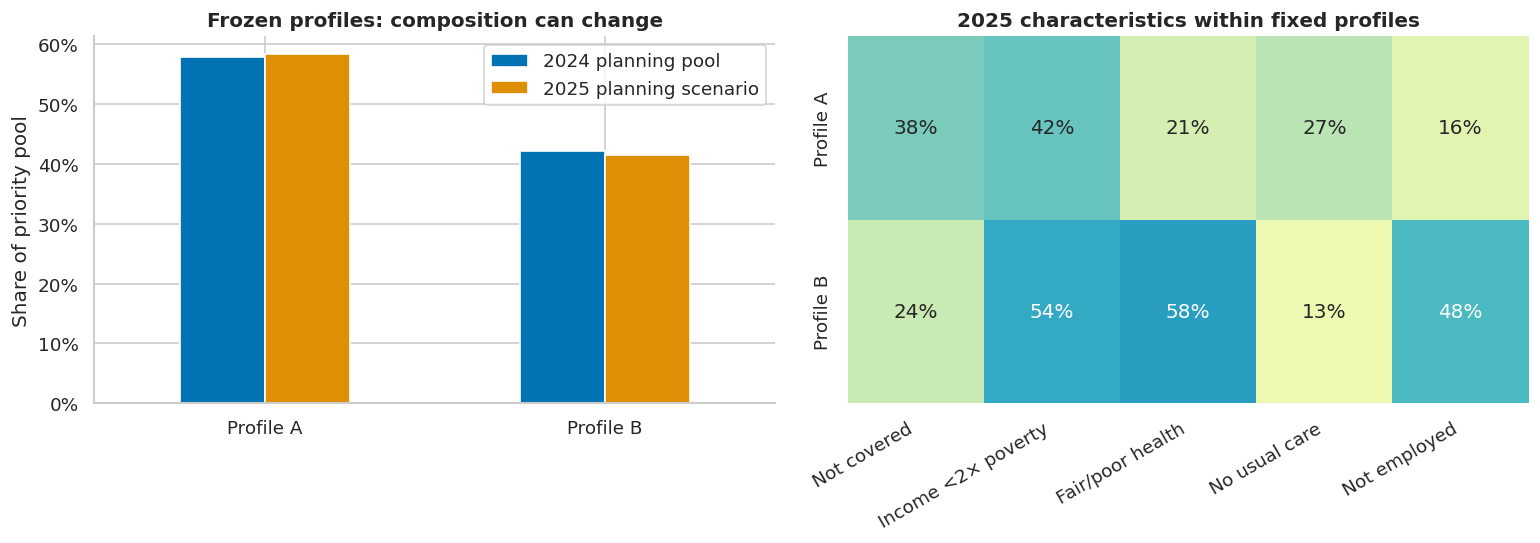

**Interpretation.** Read a profile as a combination, rather than a label that applies equally to every member. Differences between 2024 and 2025 shares show that the composition of a priority list can change even when the rules stay fixed. The classifier gives priority; the profiles suggest what to ask during follow-up. They do not demonstrate that tailored outreach reduces unmet need.

In [ ]:
evaluation_profile_rows, profile_shares = [], []
for q in [0.10, 0.20, 0.30]:
    mask = select_top_k(evaluation_scores, int(np.ceil(q * len(evaluation))))
    selected_records = evaluation.loc[mask].copy()
    labels = profile_model.predict(profile_matrix(selected_records), categorical=PROFILE_CAT_INDEX)
    summary = profile_summary(selected_records, labels)
    profile_shares.append(summary[['profile', 'share']].assign(capacity=q))
    if np.isclose(q, PROFILE_FRACTION):
        evaluation_profile_summary = summary
        evaluation_profile_records = selected_records
        evaluation_profile_labels = labels
display(evaluation_profile_summary)
display(pd.concat(profile_shares).pivot(index='profile', columns='capacity', values='share'))
display(support_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
shares_plot = pd.DataFrame({
    '2024 planning pool': planning_profile_summary.set_index('profile')['share'],
    '2025 planning scenario': evaluation_profile_summary.set_index('profile')['share']}).fillna(0)
shares_plot.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Frozen profiles: composition can change', ylabel='Share of priority pool', xlabel='')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
sns.heatmap(evaluation_profile_summary.set_index('profile')[profile_plot_columns],
            annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set(title='2025 characteristics within fixed profiles', xlabel='', ylabel='')
axes[1].set_xticklabels(['Not covered', 'Income <2× poverty', 'Fair/poor health',
                         'No usual care', 'Not employed'], rotation=30, ha='right')
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation.** Read a profile as a combination, rather than a label that applies '
                 'equally to every member. Differences between 2024 and 2025 shares show that the '
                 'composition of a priority list can change even when the rules stay fixed. The '
                 'classifier gives priority; the profiles suggest what to ask during follow-up. '
                 'They do not demonstrate that tailored outreach reduces unmet need.'))

In [ ]:
flagged_records = evaluation.loc[recall_first_predictions].copy()
flagged_clusters = profile_model.predict(profile_matrix(flagged_records), categorical=PROFILE_CAT_INDEX)
flagged_profile_summary = profile_summary(flagged_records, flagged_clusters)
print('Fixed development profiles applied to the broader recall-first flagged group:')
display(flagged_profile_summary)

Fixed development profiles applied to the broader recall-first flagged group:


,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,4134,0.5629,35.0000,0.2663,0.3832,0.1592,0.2317,0.1655,0.1381
1,Profile B,3210,0.4371,58.0000,0.1561,0.5053,0.5106,0.1106,0.4813,0.1259


## Part 9: Answering the Business Question
### What the provider can learn from the results
The following conclusion is generated from this run's measured results. It connects prediction quality to contacts and follow-up workload, rather than describing a model as good solely because of its accuracy.

In [ ]:
delta_fn = int(old_point['missed_cases'] - new_point['missed_cases'])
delta_fp = int(new_point['false_positives'] - old_point['false_positives'])
delta_fn_vs_f2 = int(old_f2_point['missed_cases'] - new_point['missed_cases'])
delta_fp_vs_f2 = int(new_point['false_positives'] - old_f2_point['false_positives'])
display(Markdown(
    '**Business decision.** Read the original-list, original-F2, revised-F2 and conservative rows together. '
    'The detailed interpretation below separates the effect of a longer flagged list from the effect '
    'of the changed forest. Use a real contact limit to choose a capacity-based list, or use the '
    'recall-focused cutoff when broader assessment is feasible. F2 is a chosen balance between '
    'case finding and false positives, not proof of an economic optimum.'
))

# These later-year results evaluate the already fixed rules.
comparison_labels = {
    'Original forest: illustrative 10% list': 'Previous illustrative 10% list',
    'Original forest: F2 cutoff': 'Original forest, recall-focused cutoff',
    'Revised forest: F2 cutoff': 'Revised forest, recall-focused cutoff',
}
business_cutoff_comparison = operating_results.loc[
    operating_results['procedure'].isin(comparison_labels),
    ['procedure', 'missed_cases', 'false_positives', 'flagged', 'recall', 'precision']].copy()
business_cutoff_comparison['procedure'] = business_cutoff_comparison['procedure'].map(comparison_labels)
display(Markdown('### 2025 comparison after fixing the cutoff on 2024\n\n'
    'These figures show the later-year consequences of the decision explained in Part 6.'))
show_cutoff_table(business_cutoff_comparison, {
    'missed_cases': '{:,.0f}', 'false_positives': '{:,.0f}', 'flagged': '{:,.0f}',
    'recall': '{:.1%}', 'precision': '{:.1%}'}, '2025 evaluation: three-way comparison')
display(Markdown(
    f"**Effect of changing the outreach rule:** the original forest's recall-focused rule "
    f"misses **{int(old_point['missed_cases'] - old_f2_point['missed_cases']):,} fewer cases** "
    f"than its earlier 10% list, while adding "
    f"**{int(old_f2_point['false_positives'] - old_point['false_positives']):,} false positives**. "
    '**Additional effect of revising the forest:** compared with the original forest using its own '
    f"recall-focused cutoff, the revised procedure misses **{delta_fn_vs_f2:,} fewer cases** and "
    f"has **{-delta_fp_vs_f2:,} fewer false positives** in this sample. "
    'Most of the reduction in missed cases comes from the broader outreach rule. '
    'The extra model changes provide a smaller measured improvement.'
))


**Business decision.** Read the original-list, original-F2, revised-F2 and conservative rows together. The detailed interpretation below separates the effect of a longer flagged list from the effect of the changed forest. Use a real contact limit to choose a capacity-based list, or use the recall-focused cutoff when broader assessment is feasible. F2 is a chosen balance between case finding and false positives, not proof of an economic optimum.

### 2025 comparison after fixing the cutoff on 2024

These figures show the later-year consequences of the decision explained in Part 6.

**2025 evaluation: three-way comparison**

,procedure,missed_cases,false_positives,flagged,recall,precision
0,Previous illustrative 10% list,798,"1,849","2,402",40.9%,23.0%
1,"Original forest, recall-focused cutoff",387,"6,483","7,447",71.4%,12.9%
2,"Revised forest, recall-focused cutoff",376,"6,369","7,344",72.2%,13.3%


**Effect of changing the outreach rule:** the original forest's recall-focused rule misses **411 fewer cases** than its earlier 10% list, while adding **4,634 false positives**. **Additional effect of revising the forest:** compared with the original forest using its own recall-focused cutoff, the revised procedure misses **11 fewer cases** and has **114 fewer false positives** in this sample. Most of the reduction in missed cases comes from the broader outreach rule. The extra model changes provide a smaller measured improvement.

### Reading the final comparison
Against the earlier illustrative 10% list, the recall-first procedure produces **422 fewer missed cases** and **4,520 more false positives**. It identifies **975 of 1,351 cases (72.2% recall)**, with **13.3% precision**. The number flagged is **7,344**; there is no fixed contact quota for this rule.

The fairer check of the changed forest is against the **original forest using its own F2 cutoff**. The revised procedure has **11 fewer missed cases** and **114 fewer false positives** in that comparison. This is the incremental model-and-feature contribution after both procedures are allowed to prioritise recall.

The **conservative alternative** has **806 missed cases** and **1,763 false positives**, giving **8 more missed cases** and **86 fewer false positives** against the earlier list. Its validation constraint is not a guarantee about later error counts.

These are measured trade-offs in the supplied sample. **Fewer misses alone should not be reported as an improvement on both errors.** The appropriate operating rule depends on how much follow-up work a provider can absorb. Every positive flag still needs confirmation of current support needs.


### What has and has not been demonstrated
The measured improvement is **more reported cases identified per fixed number of simulated contacts**. It is not evidence that outreach causes better access, that financial assistance reduces costs by a particular amount, or that the scores predict the same people's future outcomes.

Further limitations include self-report and non-response, a narrow outcome that excludes dental care, broad predictors that omit plan details and actual out-of-pocket costs, possible changes between years, and differences between national survey respondents and a provider's patients. Unweighted model development aligns with this simulated contact list; national prevalence summaries require survey weights, and formal national uncertainty would require the full survey design. A low score does not establish that somebody has no support need.

Before implementation, the provider would need to confirm that the inputs can be collected consistently **before the support decision**, validate on its own later patient records, set a real contact capacity, check who is systematically missed, and measure the results of an outreach pilot. A provider can also retain self-referral and staff referrals for people outside the ranked list. These actions address practical transfer and support access; they are not claims already established by the notebook.

**Project-level conclusion:** This revision treats missed cases as the priority while reporting the false-positive burden openly. The F2 rule and the conservative rule serve different resource trade-offs; neither guarantees both error types will improve in a later population. The profiles add a separate descriptive view of the priority population, and both parts remain a proof of concept requiring provider-specific validation.

## Appendix
### A. Key terms and reproducibility

| Term | Meaning in this project |
|---|---|
| Feature / predictor | An input such as age or coverage status |
| Target / label | The known Yes/No answer to the affordability question |
| Training | Learning patterns from labelled examples |
| Hyperparameter | A setting chosen before fitting, such as minimum leaf size |
| Validation | Development data used to compare procedures |
| Pipeline | A repeatable sequence that learns preprocessing and the model together |
| Refitting | Training the chosen procedure again on all available development years |
| Out-of-time evaluation | Checking the fixed procedure on respondents from a later year |
| Ranking versus probability | Score order can be useful even when exact risk estimates need calibration |
| Cluster / profile | A descriptive group with similar selected characteristics; not a verified support need |


### B. References
- [IPUMS NHIS: YBARCARE definition, universe, survey wording and weights](https://nhis.ipums.org/nhis-action/variables/YBARCARE).
- [IPUMS NHIS: HINOTCOVE coverage definition and codes](https://nhis.ipums.org/nhis-action/variables/HINOTCOVE).
- [IPUMS NHIS: poverty categories](https://nhis.ipums.org/nhis-action/variables/POVERTY), [education](https://nhis.ipums.org/nhis-action/variables/EDUC), [employment](https://nhis.ipums.org/nhis-action/variables/EMPSTAT), and [age](https://nhis.ipums.org/nhis-action/variables/AGE).
- [KFF (2023), Survey of Consumer Experiences with Health Insurance](https://www.kff.org/affordable-care-act/kff-survey-of-consumer-experiences-with-health-insurance/). Background context; not the model target.
- Scikit-learn: [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [nicodv/kmodes: k-prototypes implementation for mixed numerical and categorical data](https://github.com/nicodv/kmodes).